# JEPA Talking-Head: Generation-Latent Diffusion Decoder

Builds on the frozen, already-trained JEPA encoder from
`JEPA_TalkingHead_Experiments.ipynb` (that notebook's encoder-training
history and full diagnostic trail live there - this one starts fresh,
decoder-only, given how much that notebook had accumulated).

**What changed vs. the previous notebook's diffusion decoder, and why:**
today's diagnostics traced the decoder's blur problem back to
`pooled_state` still being collapsed (cosine similarity ~0.99) - varying
it barely changes the decoder's output, no matter how well-trained the
AdaLN gates get. Fixing that encoder-side collapse is a separate,
parallel thread (tracked in the Obsidian KB), not a blocker here.

Two decoder-side changes instead:

1. **Generation-latent adapter.** Audio features are available at real
   generation time (the actual driving signal) and are not collapsed,
   but were never fed to the diffusion decoder before - only to the
   ARPredictor. `GenerationLatentAdapter` combines the frozen audio
   embedding with pooled_state into the decoder's real conditioning
   signal (a VASA-1-style disentangled generation latent, separate from
   the JEPA planning state).
2. **Pretrained lip-sync perceptual loss.** Wav2Lip's SyncNet expert
   (frozen, pretrained) is used as a perceptual auxiliary loss on the
   decoder's reconstruction path - not as generation-time conditioning,
   since its face branch needs an actual image (unavailable for a
   genuinely new frame) and its audio branch expects a mel-spectrogram
   format our precomputed audio features aren't in.

Also fixed in passing: the previous notebook's `patch_projector` was
computed inside `torch.no_grad()` despite being in the optimizer's param
list, so it never actually received gradients in any prior run.


## 1. Setup


In [2]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import os

CODE_BASE = '/content/drive/MyDrive/Data/le-wm/'
REAL_DATA_PATH = '/content/drive/MyDrive/Data/TalkingHead/May_extracted'

# Point this at whichever trained-encoder checkpoint you want to build on -
# e.g. the epoch-15 H100 run from JEPA_TalkingHead_Experiments.ipynb. Only
# the JEPA encoder (model_state_dict) is used here; the old FaceDecoder in
# that checkpoint is ignored - this notebook decodes via the diffusion
# decoder instead. Set to None to auto-detect the most recently modified
# checkpoint under checkpoints/ (unreliable after Drive sync resets mtimes -
# prefer setting this explicitly once you know which run you want).
ENCODER_CHECKPOINT_PATH = None


In [4]:
# Install uv (if not already installed)
!pip install uv

# Install system dependencies required for building some Python packages (e.g., swig for box2d-py)
!apt-get update -qq > /dev/null
!apt-get install -qq -y swig > /dev/null

# Install stable-worldmodel and its dependencies using uv
!uv pip install stable-worldmodel[train,env] hydra-core torchview graphviz
!pip install -q diffusers


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.0/22.0 MB 123.2 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Using Python 3.12.13 environment at: /usr
Resolved 185 packages in 1.36s
Prepared 41 packages in 48.63s
Uninstalled 3 packages in 96ms
Installed 41 packages in 64ms
 + array-api-compat==1.15.0
 + box2d-py==2.3.5
 + cattrs==26.1.0
 + craftax==1.6.1
 + dm-control==1.0.44
 + dm-env==1.6
 + glfw==2.10.2
 + gymnasium-robotics==1.4.2
 + hydra-core==1.3.4
 + hydra-submitit-launcher==1.2.0
 + kornia==0.8.3
 + kornia-rs==0.1.14
 + labmaze==1.0.6
 + lance-namespace==0.8.6
 + lance-namespace-urllib3-client==0.8.6
 + lancedb==0.36.0
 + lightning==2.6.5
 + lightning-utilities==0.15.3
 + loguru==0.7.3
 + minari==0.5.3
 + minigrid==3.1.0
 + mujoco==3.11.0
 - numpy==2.0.2
 + numpy==2.5.1
 + ogbench==1.2.1
 + pettingzoo==1.26.1
 - pyarrow

In [5]:
os.chdir(CODE_BASE)
print(f"Changed current working directory to: {os.getcwd()}")

import sys
if CODE_BASE not in sys.path:
    sys.path.insert(0, CODE_BASE)
print(f"Added {CODE_BASE} to sys.path")

import math
import glob
import gc
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch.utils.tensorboard import SummaryWriter
from einops import rearrange
from torchvision.models.vision_transformer import vit_b_16
from tqdm import tqdm
from omegaconf import OmegaConf, DictConfig

from diffusers import DDPMScheduler, DDIMScheduler

from jepa import JEPA
from module import ARPredictor, MLP, SIGReg, Transformer, ConditionalBlock, modulate

print("Imports OK.")


Changed current working directory to: /content/drive/MyDrive/Data/le-wm
Added /content/drive/MyDrive/Data/le-wm/ to sys.path
Imports OK.


## 2. Model definitions (causal-masking fix + JEPA classes)


In [6]:
# --- Causal-masking fix (carried over) ---
# ConditionalBlock defaults causal=True, which is correct for jepa.py's own
# incremental rollout() but wrong for both the ARPredictor's fixed, fully-
# known-context parallel prediction and the diffusion decoder's Transformer
# (patch tokens / generation-latent conditioning have no causal/temporal
# order). Self-contained (imports its own deps) so it doesn't depend on
# where in the notebook it runs.
from module import ConditionalBlock, modulate


def _conditional_block_forward_causal_aware(self, x, c):
    shift_msa, scale_msa, gate_msa, shift_mlp, scale_mlp, gate_mlp = (
        self.adaLN_modulation(c).chunk(6, dim=-1)
    )
    causal = getattr(self, "causal", True)  # default True = unchanged existing behavior
    x = x + gate_msa * self.attn(modulate(self.norm1(x), shift_msa, scale_msa), causal=causal)
    x = x + gate_mlp * self.mlp(modulate(self.norm2(x), shift_mlp, scale_mlp))
    return x


ConditionalBlock.forward = _conditional_block_forward_causal_aware


# --- Core JEPA model definitions (carried over, unchanged) ---
# Kept as ONE local definition here (previously this was also imported from
# talking_head_jepa.py in the old notebook and then immediately shadowed by
# an identical local redefinition - dropped the redundant import for this
# tidied version).

class AudioFeatureEmbedder(nn.Module):
    def __init__(self, audio_feature_dim, emb_dim, hidden_dim=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(audio_feature_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, emb_dim)
        )

    def forward(self, audio_features):
        return self.net(audio_features)


class FaceEncoder(nn.Module):
    def __init__(self, image_size=224, embed_dim=768):
        super().__init__()
        self.vit = vit_b_16(weights=None)
        self.vit.heads = nn.Identity()
        self.embed_dim = embed_dim

    def forward(self, pixels, **kwargs):
        if len(pixels.shape) == 5:
            pixels = rearrange(pixels, 'b t c h w -> (b t) c h w')

        x = self.vit._process_input(pixels)
        n = x.shape[0]

        batch_class_token = self.vit.class_token.expand(n, -1, -1)
        x = torch.cat([batch_class_token, x], dim=1)
        x = self.vit.encoder(x)

        class Output:
            pass
        out = Output()
        out.last_hidden_state = x
        return out


class TalkingHeadJEPA(nn.Module):
    def __init__(
        self,
        image_size=224,
        audio_feature_dim=512,
        embed_dim=256,
        hidden_dim=256,
        history_size=4,
        audio_expert=None,
        freeze_audio_expert_params=False
    ):
        super().__init__()
        self.history_size = history_size
        self.embed_dim = embed_dim

        self.face_encoder = FaceEncoder(image_size=image_size, embed_dim=embed_dim)

        if not audio_expert:
            self.audio_embedder = AudioFeatureEmbedder(audio_feature_dim=audio_feature_dim, emb_dim=embed_dim)
        else:
            self.audio_embedder = audio_expert
            if freeze_audio_expert_params:
                for param in self.audio_embedder.parameters():
                    param.requires_grad = False

        self.predictor = ARPredictor(
            num_frames=history_size,
            input_dim=embed_dim,
            hidden_dim=hidden_dim,
            output_dim=embed_dim,
            depth=6,
            heads=8,
            mlp_dim=hidden_dim * 4,
        )
        for _block in self.predictor.transformer.layers:
            _block.causal = False

        self.projector = MLP(input_dim=768, output_dim=embed_dim, hidden_dim=1024, norm_fn=nn.BatchNorm1d)
        self.pred_proj = MLP(input_dim=embed_dim, output_dim=embed_dim, hidden_dim=1024, norm_fn=nn.BatchNorm1d)

        self.jepa = JEPA(
            encoder=self.face_encoder,
            predictor=self.predictor,
            action_encoder=self.audio_embedder,
            projector=self.projector,
            pred_proj=self.pred_proj,
        )

        self.sigreg = SIGReg()
        self.sigreg_weight = 1.0

    def encode(self, batch):
        encoder_out = self.face_encoder(batch["pixels"], interpolate_pos_encoding=True)
        raw_features = encoder_out.last_hidden_state

        if len(raw_features.shape) == 3:
            raw_features = raw_features[:, 0]

        emb = self.projector(raw_features)
        act_emb = self.audio_embedder(batch["action"])

        return {"emb": emb, "act_emb": act_emb}


class ResBlock(nn.Module):
    """Reused by PatchGridToImageDecoder below."""
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        self.relu = nn.LeakyReLU(0.2, inplace=True)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        return x + self.conv2(self.relu(self.bn1(self.conv1(x))))


print("Model definitions loaded (causal-masking fix applied, JEPA classes, ResBlock).")


Model definitions loaded (causal-masking fix applied, JEPA classes, ResBlock).


## 3. Load the frozen, already-trained JEPA encoder


In [7]:
# --- Load the frozen, already-trained JEPA encoder ---
# This notebook does NOT retrain the encoder. It builds on whatever
# checkpoint you already have (e.g. from the 15-epoch H100 run in
# JEPA_TalkingHead_Experiments.ipynb), frozen, and focuses entirely on the
# decoder side: adding an audio-conditioned generation latent and a
# pretrained lip-sync perceptual loss. pooled_state is known to still be
# collapsed (cosine similarity ~0.99) - fixing that is a separate, parallel
# thread, not a blocker for this notebook.

def clear_gpu():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

clear_gpu()

CONFIG_FILE_PATH = os.path.join(CODE_BASE, 'config', 'train', 'talking_head.yaml')
cfg = OmegaConf.merge(
    OmegaConf.load(CONFIG_FILE_PATH),
    OmegaConf.create({"model": {"audio_feature_dim": 512}}),  # must match the checkpoint's training config
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_frozen_encoder(cfg, checkpoint_path=None, device=None):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")

    if checkpoint_path is None:
        candidates = glob.glob(os.path.join("checkpoints", "*.pth"))
        if not candidates:
            raise FileNotFoundError(
                "No checkpoints found in 'checkpoints/'. Set ENCODER_CHECKPOINT_PATH explicitly, "
                "or train an encoder first in JEPA_TalkingHead_Experiments.ipynb."
            )
        checkpoint_path = max(candidates, key=os.path.getctime)
        print("ENCODER_CHECKPOINT_PATH was None - auto-detected latest by mtime "
              "(unreliable after Drive sync; verify this is the checkpoint you want):")
    print(f"Loading frozen encoder from: {checkpoint_path}")

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

    encoder_model = TalkingHeadJEPA(
        image_size=cfg.model.image_size,
        audio_feature_dim=cfg.model.audio_feature_dim,
        embed_dim=cfg.model.embed_dim,
        hidden_dim=cfg.model.hidden_dim,
        history_size=cfg.model.history_size,
    ).to(device)
    encoder_model.load_state_dict(checkpoint["model_state_dict"])

    # Frozen throughout - no gradients, eval() mode (BatchNorm1d in
    # model.jepa.projector uses running stats only in eval mode; torch.no_grad()
    # alone does not stop it from updating running stats in train() mode).
    for p in encoder_model.parameters():
        p.requires_grad = False
    encoder_model.eval()

    print(f"Loaded (encoder trained through epoch {checkpoint.get('epoch', '?')}). Frozen, eval() mode.")
    return encoder_model


model = load_frozen_encoder(cfg, checkpoint_path=ENCODER_CHECKPOINT_PATH, device=device)


ENCODER_CHECKPOINT_PATH was None - auto-detected latest by mtime (unreliable after Drive sync; verify this is the checkpoint you want):
Loading frozen encoder from: checkpoints/talking_head_ckpt_20260727_111957.pth
Loaded (encoder trained through epoch 14). Frozen, eval() mode.


## 4. Dataset


In [8]:
class SyncTalkDataset(Dataset):
    def __init__(self, data_root, seq_len=8, image_size=224):
        self.data_root = Path(data_root)
        self.seq_len = seq_len
        self.image_size = image_size

        self.image_paths = sorted(list((self.data_root / 'gt_imgs').glob('*.jpg')))
        if not self.image_paths:
            self.image_paths = sorted(list((self.data_root / 'ori_imgs').glob('*.jpg')))

        audio_path = self.data_root / 'aud_ave.npy'
        if audio_path.exists():
            self.audio_features = np.load(audio_path)
            print(f"Loaded audio features: {self.audio_features.shape}")
        else:
            print(f"Warning: {audio_path} not found, using dummy audio")
            self.audio_features = np.zeros((len(self.image_paths), 1024))

    def __len__(self):
        return len(self.image_paths) - self.seq_len

    def __getitem__(self, idx):
        frames = []
        for i in range(idx, idx + self.seq_len):
            img = cv2.imread(str(self.image_paths[i]))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (self.image_size, self.image_size))
            frames.append(img)

        frames = np.stack(frames).astype(np.float32) / 255.0
        frames = torch.from_numpy(frames).permute(0, 3, 1, 2)  # (T, C, H, W)

        audio_idx = min(idx, len(self.audio_features) - self.seq_len)
        audio = self.audio_features[audio_idx: audio_idx + self.seq_len]
        audio = torch.from_numpy(audio).float()

        return frames, audio


print("SyncTalkDataset defined.")


SyncTalkDataset defined.


## 5. Patch-token extraction


In [9]:
# --- Patch-token extraction helper (carried over, unchanged) ---
# The FaceEncoder returns the FULL token sequence (CLS + patches) as
# last_hidden_state. pooled_state (via the collapsed projector/BatchNorm
# path) is kept for reference/diagnostics only in this notebook - the
# generation latent below is built from patch tokens + audio instead.

def encode_cls_and_patches(face_encoder, projector, patch_projector, pixels):
    """
    Returns:
        pooled_state: (B, embed_dim)   - existing JEPA state (known collapsed)
        patch_tokens: (B, N, PATCH_DIM) - projected patch-token grid (N=196 for ViT-B/16 @ 224px)
    """
    out = face_encoder(pixels, interpolate_pos_encoding=True)
    tokens = out.last_hidden_state
    cls_tok = tokens[:, 0]
    patch_tok_raw = tokens[:, 1:]
    pooled_state = projector(cls_tok)
    patch_tokens = patch_projector(patch_tok_raw)
    return pooled_state, patch_tokens


print("encode_cls_and_patches() defined.")


encode_cls_and_patches() defined.


## 6. Frozen pretrained lip-sync expert (Wav2Lip SyncNet)

Downloads the public checkpoint on first run (~197MB, from a
community HF mirror of the official Wav2Lip release - see notebook
chat history / KB for provenance notes). Used only as a perceptual
auxiliary loss below, not as generation-time conditioning.


In [10]:
# --- Wav2Lip SyncNet (Prajwal et al. 2020, arXiv:2008.10010) ---
# Architecture copied verbatim from github.com/Rudrabha/Wav2Lip
# (models/syncnet.py, models/conv.py) so the pretrained checkpoint's
# state_dict keys match exactly.
#
# Role in THIS notebook: a frozen, pretrained mouth/expression feature
# extractor used as a PERCEPTUAL AUXILIARY LOSS on the decoder's
# reconstruction path (face_encoder branch only) - not as a generation-time
# conditioning input. Its face branch needs an actual face image, which
# isn't available when generating a genuinely new/predicted frame, and its
# audio branch expects raw mel-spectrogram windows in Wav2Lip's specific
# preprocessing format, which our precomputed `aud_ave.npy` features aren't
# in - so using it as real generation-time conditioning isn't feasible
# without solving that separately. As a perceptual loss on frames we DO have
# ground truth for during training, neither limitation applies.


class Conv2d(nn.Module):
    def __init__(self, cin, cout, kernel_size, stride, padding, residual=False, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv_block = nn.Sequential(
            nn.Conv2d(cin, cout, kernel_size, stride, padding),
            nn.BatchNorm2d(cout)
        )
        self.act = nn.ReLU()
        self.residual = residual

    def forward(self, x):
        out = self.conv_block(x)
        if self.residual:
            out += x
        return self.act(out)


class SyncNet_color(nn.Module):
    def __init__(self):
        super().__init__()

        self.face_encoder = nn.Sequential(
            Conv2d(15, 32, kernel_size=(7, 7), stride=1, padding=3),

            Conv2d(32, 64, kernel_size=5, stride=(1, 2), padding=1),
            Conv2d(64, 64, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(64, 64, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            Conv2d(128, 128, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(128, 128, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(128, 128, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(128, 256, kernel_size=3, stride=2, padding=1),
            Conv2d(256, 256, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(256, 256, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(256, 512, kernel_size=3, stride=2, padding=1),
            Conv2d(512, 512, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(512, 512, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(512, 512, kernel_size=3, stride=2, padding=1),
            Conv2d(512, 512, kernel_size=3, stride=1, padding=0),
            Conv2d(512, 512, kernel_size=1, stride=1, padding=0),
        )

        self.audio_encoder = nn.Sequential(
            Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            Conv2d(32, 32, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(32, 32, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(32, 64, kernel_size=3, stride=(3, 1), padding=1),
            Conv2d(64, 64, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(64, 64, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(64, 128, kernel_size=3, stride=3, padding=1),
            Conv2d(128, 128, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(128, 128, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(128, 256, kernel_size=3, stride=(3, 2), padding=1),
            Conv2d(256, 256, kernel_size=3, stride=1, padding=1, residual=True),
            Conv2d(256, 256, kernel_size=3, stride=1, padding=1, residual=True),

            Conv2d(256, 512, kernel_size=3, stride=1, padding=0),
            Conv2d(512, 512, kernel_size=1, stride=1, padding=0),
        )

    def forward(self, audio_sequences, face_sequences):
        face_embedding = self.face_encoder(face_sequences)
        audio_embedding = self.audio_encoder(audio_sequences)

        audio_embedding = audio_embedding.view(audio_embedding.size(0), -1)
        face_embedding = face_embedding.view(face_embedding.size(0), -1)

        audio_embedding = F.normalize(audio_embedding, p=2, dim=1)
        face_embedding = F.normalize(face_embedding, p=2, dim=1)

        return audio_embedding, face_embedding


SYNCNET_CKPT_PATH = "lipsync_expert.pth"
SYNCNET_CKPT_URL = "https://huggingface.co/camenduru/Wav2Lip/resolve/main/checkpoints/lipsync_expert.pth?download=true"

if not os.path.exists(SYNCNET_CKPT_PATH):
    print(f"Downloading SyncNet checkpoint from {SYNCNET_CKPT_URL} ...")
    os.system(f'wget -q -O "{SYNCNET_CKPT_PATH}" "{SYNCNET_CKPT_URL}"')

syncnet = SyncNet_color().to(device)

_raw_ckpt = torch.load(SYNCNET_CKPT_PATH, map_location=device)
_state_dict = _raw_ckpt.get("state_dict", _raw_ckpt)
# Wav2Lip's released checkpoints were saved from a DataParallel-wrapped
# model, so keys are prefixed with "module." - strip it if present.
_state_dict = {k.replace("module.", "", 1) if k.startswith("module.") else k: v
               for k, v in _state_dict.items()}
_missing, _unexpected = syncnet.load_state_dict(_state_dict, strict=False)
print(f"SyncNet checkpoint loaded. missing keys: {len(_missing)}, unexpected keys: {len(_unexpected)}")
if _missing or _unexpected:
    print("  (if either list is non-trivially large, the checkpoint didn't match this "
          "architecture as expected - print _missing/_unexpected to inspect)")

for p in syncnet.parameters():
    p.requires_grad = False
syncnet.eval()
print("SyncNet frozen, eval() mode.")


@torch.no_grad()
def make_mouth_window(frames_btchw, num_frames=5, size=96):
    """
    frames_btchw: (B, T, 3, H, W) in [0, 1], T >= num_frames.
    Crops the lower half of each frame (mouth region, matching Wav2Lip's own
    preprocessing convention), resizes to `size`x`size`, takes the first
    `num_frames` consecutive frames, and concatenates them along the channel
    dim -> (B, 3*num_frames, size, size), SyncNet's expected face_sequences
    input shape.
    """
    B, T, C, H, W = frames_btchw.shape
    assert T >= num_frames, f"need at least {num_frames} consecutive frames, got {T}"
    window = frames_btchw[:, :num_frames]                      # (B, num_frames, 3, H, W)
    mouth = window[:, :, :, H // 2:, :]                         # lower half
    mouth = rearrange(mouth, "b t c h w -> (b t) c h w")
    mouth = F.interpolate(mouth, size=(size, size), mode="bilinear", align_corners=False)
    mouth = rearrange(mouth, "(b t) c h w -> b (t c) h w", b=B, t=num_frames)
    return mouth


def syncnet_perceptual_loss(decoded_window_btchw, gt_window_btchw, num_frames=5):
    """
    Cosine-distance loss between SyncNet's face_encoder embedding of a
    decoded 5-frame mouth window vs. the ground-truth window. A pretrained,
    non-collapsed perceptual signal on top of raw pixel MSE (recon_loss),
    aimed at the blur/averaging failure mode the visual checks showed -
    matching mouth-shape features, not just matching pixels on average.
    """
    decoded_mouth = make_mouth_window(decoded_window_btchw, num_frames=num_frames)
    with torch.no_grad():
        gt_mouth = make_mouth_window(gt_window_btchw, num_frames=num_frames)
    # gt path has no_grad (target), decoded path keeps grad (this is what we train)
    decoded_mouth = rearrange(decoded_mouth, "b c h w -> b c h w")  # no-op, keeps grad graph explicit
    _, decoded_embed = syncnet(torch.zeros(decoded_mouth.size(0), 1, 80, 16, device=decoded_mouth.device),
                                decoded_mouth)
    with torch.no_grad():
        _, gt_embed = syncnet(torch.zeros(gt_mouth.size(0), 1, 80, 16, device=gt_mouth.device), gt_mouth)
    return (1 - F.cosine_similarity(decoded_embed, gt_embed, dim=-1)).mean()


print("syncnet_perceptual_loss() defined (face_encoder branch only - audio_encoder is "
      "run on a dummy zero tensor purely to satisfy SyncNet's forward() signature and "
      "is not part of the loss).")


SyncNet checkpoint loaded. missing keys: 0, unexpected keys: 0
SyncNet frozen, eval() mode.
syncnet_perceptual_loss() defined (face_encoder branch only - audio_encoder is run on a dummy zero tensor purely to satisfy SyncNet's forward() signature and is not part of the loss).


## 7. Diffusion decoder architecture + generation-latent adapter


In [11]:
# --- Diffusion decoder backbone (carried over) + NEW generation-latent adapter ---
#
# Key change from JEPA_TalkingHead_Experiments.ipynb: the decoder's AdaLN
# conditioning was pooled_state alone. Tracing today's diagnostics found two
# things: (1) pooled_state barely affects the output (isolation-test ratio
# 0.0014), best explained by it still being collapsed; (2) audio_features
# were never fed to the diffusion decoder at all - only to the ARPredictor.
#
# v2 fix: the first version of GenerationLatentAdapter fed in
# model.audio_embedder's output, assuming audio would be a healthy signal.
# It wasn't - audio_embed turned out collapsed too (cosine similarity
# 0.9931), since that small MLP was trained jointly with the same
# collapse-prone JEPA objective. But the RAW aud_ave.npy features feeding
# that MLP checked out healthy (cosine similarity 0.6988, real variance) -
# so the fix is to skip the frozen, collapsed audio_embedder entirely and
# give the generation latent its own FRESH, trainable projection of the raw
# audio features instead. No encoder retrain needed for this fix.

class TimestepEmbedding(nn.Module):
    def __init__(self, dim, freq_dim=256):
        super().__init__()
        self.freq_dim = freq_dim
        self.mlp = nn.Sequential(nn.Linear(freq_dim, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, t):
        half = self.freq_dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device).float() / half)
        args = t.float()[:, None] * freqs[None]
        emb = torch.cat([torch.cos(args), torch.sin(args)], dim=-1)
        return self.mlp(emb)


class GenerationLatentAdapter(nn.Module):
    """
    VASA-1-style disentangled generation latent: a small trainable adapter
    off the (frozen) JEPA representation, rather than repurposing
    pooled_state directly as the decoder's conditioning. Combines a FRESH,
    trainable projection of RAW audio_features (real per-frame variance
    confirmed, cosine similarity 0.6988 - not the frozen, collapsed
    model.audio_embedder) with pooled_state (kept for now, in case its
    collapse gets fixed later - not the sole signal).
    """
    def __init__(self, embed_dim=256, audio_feature_dim=512, gen_dim=256, hidden_dim=512):
        super().__init__()
        self.audio_proj = nn.Linear(audio_feature_dim, embed_dim)
        self.net = nn.Sequential(
            nn.Linear(embed_dim * 2, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, gen_dim),
        )
        self.null_cond = nn.Parameter(torch.zeros(gen_dim))  # CFG-style unconditional embedding
        # 2026-07-30: lets training force reliance on audio alone for a fraction of steps
        # (pooled_dropout_prob in train_diffusion_decoder) - distinct from null_cond/cond_dropout
        # above, which drops the WHOLE output. Motivated by two diagnostics: (1) the weight-balance
        # check showed net[0] does NOT under-weight audio (ratio audio/pooled = 1.15, audio
        # slightly larger); (2) the output-diversity check showed audio actually drives MORE
        # output diversity than pooled_state (2.4x, cos_sim 0.14 vs 0.88) - so the audio_only
        # correctness gap is downstream (how the diffusion decoder uses that variation), not
        # gen_latent_adapter under-using audio. This dropout still targets forcing the decoder
        # to learn to use audio well, complementary to the syncnet_loss_weight increase.
        self.null_pooled_state = nn.Parameter(torch.zeros(embed_dim))

    def forward(self, pooled_state, raw_audio):
        audio_embed = self.audio_proj(raw_audio)
        return self.net(torch.cat([pooled_state, audio_embed], dim=-1))


class PatchTokenDiffusionDecoder(nn.Module):
    """
    DiT-style denoiser operating on the ViT patch-token grid, conditioned on
    the GenerationLatentAdapter's output (not raw pooled_state) + diffusion
    timestep, via the same AdaLN-zero ConditionalBlock used by ARPredictor.
    """
    def __init__(self, patch_dim=128, num_patches=196, cond_dim=256, depth=4, heads=4, mlp_dim=512):
        super().__init__()
        self.pos_embedding = nn.Parameter(torch.randn(1, num_patches, patch_dim) * 0.02)
        self.time_embed = TimestepEmbedding(cond_dim)
        self.cond_proj = nn.Linear(cond_dim, patch_dim)
        self.transformer = Transformer(
            input_dim=patch_dim,
            hidden_dim=patch_dim,
            output_dim=patch_dim,
            depth=depth,
            heads=heads,
            dim_head=max(patch_dim // heads, 8),
            mlp_dim=mlp_dim,
            block_class=ConditionalBlock,
        )
        for _block in self.transformer.layers:
            _block.causal = False

    def forward(self, noisy_patches, timesteps, cond_vec):
        """
        cond_vec: (B, cond_dim) - GenerationLatentAdapter's output now,
                  not raw pooled_state.
        """
        t_emb = self.time_embed(timesteps)
        c = self.cond_proj(cond_vec + t_emb)
        c = c.unsqueeze(1).expand(-1, noisy_patches.size(1), -1)
        x = noisy_patches + self.pos_embedding
        return self.transformer(x, c)


class PatchGridToImageDecoder(nn.Module):
    """Decodes a denoised (B, 196, patch_dim) grid back to a 224x224 RGB image."""
    def __init__(self, patch_dim=128, grid=14):
        super().__init__()
        self.grid = grid
        self.proj = nn.Linear(patch_dim, 256)
        self.deconv = nn.Sequential(
            ResBlock(256),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  # 28x28
            nn.Conv2d(256, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            ResBlock(128),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  # 56x56
            nn.Conv2d(128, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2, inplace=True),
            ResBlock(64),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  # 112x112
            nn.Conv2d(64, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2, inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),  # 224x224
            nn.Conv2d(32, 3, kernel_size=3, padding=1), nn.Sigmoid(),
        )

    def forward(self, patch_grid):
        b, n, d = patch_grid.shape
        x = self.proj(patch_grid)
        x = x.transpose(1, 2).reshape(b, 256, self.grid, self.grid)
        return self.deconv(x)


print("Decoder architecture defined: PatchTokenDiffusionDecoder conditions on "
      "GenerationLatentAdapter(pooled_state, RAW audio_features) - audio now goes through "
      "its own fresh trainable projection, not the frozen/collapsed model.audio_embedder.")


Decoder architecture defined: PatchTokenDiffusionDecoder conditions on GenerationLatentAdapter(pooled_state, RAW audio_features) - audio now goes through its own fresh trainable projection, not the frozen/collapsed model.audio_embedder.


In [26]:
import torchvision


class VGGPerceptualLoss(nn.Module):
    """
    Frozen VGG16 perceptual loss. Compares feature-map activations at
    relu1_2/relu2_2/relu3_3/relu4_3 (the standard Johnson et al. layer
    choices) between decoded and ground-truth images, instead of raw pixels.
    Frozen throughout - no gradients flow into VGG's own weights, only back
    through `decoded` into whatever produced it (patch_pixel_decoder /
    patch_projector).
    """
    def __init__(self, layer_ids=(3, 8, 15, 22), device="cuda"):
        super().__init__()
        weights = torchvision.models.VGG16_Weights.IMAGENET1K_V1
        vgg = torchvision.models.vgg16(weights=weights).features.to(device).eval()
        for p in vgg.parameters():
            p.requires_grad = False
        self.vgg = vgg
        self.layer_ids = set(layer_ids)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def _normalize(self, x):
        return (x - self.mean) / self.std

    def _features(self, x):
        x = self._normalize(x)
        feats = []
        max_layer = max(self.layer_ids)
        for i, layer in enumerate(self.vgg):
            x = layer(x)
            if i in self.layer_ids:
                feats.append(x)
            if i == max_layer:
                break
        return feats

    def forward(self, decoded, gt, size=112):
        """decoded: (B, 3, H, W) in [0, 1], keeps grad. gt: (B, 3, H, W) in [0, 1], no grad needed."""
        decoded = F.interpolate(decoded, size=(size, size), mode="bilinear", align_corners=False)
        with torch.no_grad():
            gt = F.interpolate(gt, size=(size, size), mode="bilinear", align_corners=False)
        decoded_feats = self._features(decoded)
        with torch.no_grad():
            gt_feats = self._features(gt)
        loss = 0.0
        for df, gf in zip(decoded_feats, gt_feats):
            loss = loss + F.l1_loss(df, gf)
        return loss / len(decoded_feats)


print("VGGPerceptualLoss defined (frozen VGG16, relu1_2/relu2_2/relu3_3/relu4_3 feature L1). "
      "Downloads ImageNet-pretrained weights on first use (cached after).")

VGGPerceptualLoss defined (frozen VGG16, relu1_2/relu2_2/relu3_3/relu4_3 feature L1). Downloads ImageNet-pretrained weights on first use (cached after).


## 8. Training loop

Run this to train (or resume) the decoder. Example:
```python
diffusion_decoder, patch_pixel_decoder, patch_projector, gen_latent_adapter, noise_scheduler, ddim_scheduler = \\
    train_diffusion_decoder(model, cfg, num_epochs=10, batch_size=32)
```
To resume from a checkpoint:
```python
    train_diffusion_decoder(model, cfg, num_epochs=10, batch_size=32,
        resume_from="diffusion_checkpoints_genlatent/diffusion_decoder_genlatent_epoch_10.pth")
```


In [28]:
# --- Diffusion decoder training loop, v2: generation latent + SyncNet perceptual loss ---
import os


def train_diffusion_decoder(
    model,
    cfg,
    num_epochs=10,
    batch_size=32,
    val_frac=0.1,
    patch_dim=128,
    gen_dim=256,
    lr=1e-4,
    recon_loss_weight=0.1,
    syncnet_loss_weight=0.02,
    patch_sigreg_weight=5.0,
    gen_latent_sigreg_weight=5.0,
    direct_recon_loss_weight=1.0,
    perceptual_loss_weight=1.0,
    cond_dropout_prob=0.15,
    pooled_dropout_prob=0.0,
    reset_optimizer=False,
    checkpoint_dir="diffusion_checkpoints_genlatent",
    checkpoint_every_epochs=2,
    log_every_steps=50,
    resume_from=None,
):
    os.makedirs(checkpoint_dir, exist_ok=True)
    model.eval()  # frozen encoder throughout

    full_dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    val_size = max(1, int(len(full_dataset) * val_frac))
    train_size = len(full_dataset) - val_size
    train_dataset, val_dataset = random_split(
        full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(3072)
    )
    print(f"Dataset split: {train_size} train sequences, {val_size} val sequences")

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=min(batch_size, val_size), shuffle=True, num_workers=2)

    patch_projector = nn.Linear(768, patch_dim).to(device)
    gen_latent_adapter = GenerationLatentAdapter(
        embed_dim=model.embed_dim, audio_feature_dim=cfg.model.audio_feature_dim, gen_dim=gen_dim
    ).to(device)
    diffusion_decoder = PatchTokenDiffusionDecoder(patch_dim=patch_dim, cond_dim=gen_dim).to(device)
    patch_pixel_decoder = PatchGridToImageDecoder(patch_dim=patch_dim).to(device)
    vgg_perceptual_loss = VGGPerceptualLoss(device=device).to(device)

    noise_scheduler = DDPMScheduler(num_train_timesteps=1000)
    ddim_scheduler = DDIMScheduler(num_train_timesteps=1000)

    opt = torch.optim.AdamW(
        list(diffusion_decoder.parameters())
        + list(patch_pixel_decoder.parameters())
        + list(patch_projector.parameters())
        + list(gen_latent_adapter.parameters()),
        lr=lr,
    )

    start_epoch = 0
    if resume_from and os.path.exists(resume_from):
        print(f"Resuming decoder training from checkpoint: {resume_from}")
        ckpt = torch.load(resume_from, map_location=device)
        diffusion_decoder.load_state_dict(ckpt["diffusion_decoder_state_dict"])
        patch_pixel_decoder.load_state_dict(ckpt["patch_pixel_decoder_state_dict"])
        patch_projector.load_state_dict(ckpt["patch_projector_state_dict"])
        gen_latent_adapter.load_state_dict(ckpt["gen_latent_adapter_state_dict"], strict=False)
        if not reset_optimizer:
            opt.load_state_dict(ckpt["optimizer_state_dict"])
        else:
            print("reset_optimizer=True: fresh optimizer (null_cond/null_pooled_state are new "
                  "params - old optimizer state no longer matches in shape).")
        start_epoch = ckpt["epoch"] + 1
        print(f"Resuming from epoch {start_epoch}")

    writer = SummaryWriter(f"runs/diffusion_decoder_genlatent_{datetime.now().strftime('%Y%m%d_%H%M%S')}")
    global_step = 0

    def encode_batch(frames, audio):
        frames = frames.to(device)
        audio = audio.to(device)
        B, T, C, H, W = frames.shape
        flat = rearrange(frames, "b t c h w -> (b t) c h w")
        flat_audio = rearrange(audio, "b t d -> (b t) d")

        with torch.no_grad():  # ONLY the frozen encoder forward pass
            enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
            tokens = enc_out.last_hidden_state
            cls_tok = tokens[:, 0]
            patch_tok_raw = tokens[:, 1:]
            pooled_state = model.jepa.projector(cls_tok)
            # model.audio_embedder is NOT used here anymore - its output was found to be
            # collapsed (cosine similarity 0.9931), while the RAW audio_features feeding
            # it checked out healthy (0.6988) - so gen_latent_adapter gets the raw features
            # directly and does its own fresh projection instead.

        # Trainable - must be OUTSIDE no_grad (this was the bug in the previous notebook)
        patch_tok = patch_projector(patch_tok_raw)

        # 2026-07-30: pooled_state dropout - forces gen_latent_adapter to produce a usable
        # output from audio alone for a fraction of steps. Only affects the INPUT to the
        # adapter (a local variable here); the pooled_state returned below is untouched.
        if gen_latent_adapter.training and pooled_dropout_prob > 0:
            pooled_drop_mask = (
                torch.rand(pooled_state.size(0), device=device) < pooled_dropout_prob
            ).unsqueeze(-1)
            pooled_state_in = torch.where(
                pooled_drop_mask,
                gen_latent_adapter.null_pooled_state.unsqueeze(0).expand_as(pooled_state),
                pooled_state,
            )
        else:
            pooled_state_in = pooled_state
        real_gen_latent = gen_latent_adapter(pooled_state_in, flat_audio)

        # CFG-style cond dropout: only during training (gen_latent_adapter.train()), so the
        # model can't get away with a cond-independent shortcut (matching check showed total
        # collapse - every vary= variant's full-DDIM output matched the same GT frame,
        # including audio_only whose raw audio input is confirmed non-collapsed).
        if gen_latent_adapter.training and cond_dropout_prob > 0:
            drop_mask = (torch.rand(real_gen_latent.size(0), device=device) < cond_dropout_prob).unsqueeze(-1)
            gen_latent = torch.where(
                drop_mask, gen_latent_adapter.null_cond.unsqueeze(0).expand_as(real_gen_latent), real_gen_latent
            )
        else:
            gen_latent = real_gen_latent

        return flat, pooled_state, patch_tok, gen_latent, real_gen_latent, B, T

    @torch.no_grad()
    def cross_frame_ratio(flat, patch_tok, gen_latent, num_show=8, low_noise_timestep=50):
        n = min(num_show, flat.size(0))
        idx = torch.randperm(flat.size(0))[:n]
        gt, tok, cond = flat[idx], patch_tok[idx], gen_latent[idx]

        t_low = torch.full((n,), low_noise_timestep, device=device, dtype=torch.long)
        noise = torch.randn_like(tok)
        noisy_low = noise_scheduler.add_noise(tok, noise, t_low)
        pred_noise_low = diffusion_decoder(noisy_low, t_low, cond)
        alpha_low = noise_scheduler.alphas_cumprod[t_low].to(device).view(-1, 1, 1)
        denoised_low = (noisy_low - (1 - alpha_low).sqrt() * pred_noise_low) / alpha_low.sqrt()
        decoded_low = patch_pixel_decoder(denoised_low)

        def mean_pairwise_l1(x):
            total, count = 0.0, 0
            for i in range(x.size(0)):
                for j in range(i + 1, x.size(0)):
                    total += (x[i] - x[j]).abs().mean().item()
                    count += 1
            return total / max(count, 1)

        gt_pw = mean_pairwise_l1(gt)
        low_pw = mean_pairwise_l1(decoded_low)
        return (low_pw / gt_pw) if gt_pw > 0 else float("nan")

    def sync_window_loss(flat, patch_tok, gen_latent, B, T, num_frames=5):
        """SyncNet perceptual loss on the first `num_frames` consecutive frames of
        each sequence in the batch, reusing already-computed patch_tok/gen_latent
        (no extra encoder forward needed)."""
        if syncnet_loss_weight <= 0:
            return torch.tensor(0.0, device=device)
        gt_frames = rearrange(flat, "(b t) c h w -> b t c h w", b=B, t=T)[:, :num_frames]
        tok_win = rearrange(patch_tok, "(b t) n d -> b t n d", b=B, t=T)[:, :num_frames]
        cond_win = rearrange(gen_latent, "(b t) d -> b t d", b=B, t=T)[:, :num_frames]
        tok_win = rearrange(tok_win, "b t n d -> (b t) n d")
        cond_win = rearrange(cond_win, "b t d -> (b t) d")

        t_low = torch.full((tok_win.size(0),), 50, device=device, dtype=torch.long)
        noise = torch.randn_like(tok_win)
        noisy_low = noise_scheduler.add_noise(tok_win, noise, t_low)
        pred_noise_low = diffusion_decoder(noisy_low, t_low, cond_win)
        alpha_low = noise_scheduler.alphas_cumprod[t_low].to(device).view(-1, 1, 1)
        denoised_low = (noisy_low - (1 - alpha_low).sqrt() * pred_noise_low) / alpha_low.sqrt()
        decoded_flat = patch_pixel_decoder(denoised_low)
        decoded_window = rearrange(decoded_flat, "(b t) c h w -> b t c h w", b=B, t=num_frames)

        return syncnet_perceptual_loss(decoded_window, gt_frames, num_frames=num_frames)

    for epoch in range(start_epoch, start_epoch + num_epochs):
        diffusion_decoder.train()
        patch_pixel_decoder.train()
        patch_projector.train()
        gen_latent_adapter.train()

        epoch_diff_loss, epoch_recon_loss, epoch_sync_loss, epoch_sigreg_loss, epoch_gen_latent_sigreg_loss, n_batches = 0.0, 0.0, 0.0, 0.0, 0.0, 0
        epoch_direct_recon_loss, epoch_perceptual_loss = 0.0, 0.0
        pbar = tqdm(train_loader, desc=f"Diffusion decoder epoch {epoch+1}/{start_epoch + num_epochs}")
        for frames, audio in pbar:
            flat_frames, pooled_state, patch_tok, gen_latent, real_gen_latent, B, T = encode_batch(frames, audio)

            opt.zero_grad()
            noise = torch.randn_like(patch_tok)
            timesteps = torch.randint(
                0, noise_scheduler.config.num_train_timesteps, (patch_tok.size(0),), device=device
            ).long()
            noisy_patch_tok = noise_scheduler.add_noise(patch_tok, noise, timesteps)

            pred_noise = diffusion_decoder(noisy_patch_tok, timesteps, gen_latent)
            diff_loss = F.mse_loss(pred_noise, noise)

            with torch.no_grad():  # superseded by direct_recon_loss - kept for monitoring only
                alpha_prod = noise_scheduler.alphas_cumprod[timesteps].to(device).view(-1, 1, 1)
                denoised_est = (noisy_patch_tok - (1 - alpha_prod).sqrt() * pred_noise.detach()) / alpha_prod.sqrt()
                decoded = patch_pixel_decoder(denoised_est)
                recon_loss = F.mse_loss(decoded, flat_frames)

            sync_loss = sync_window_loss(flat_frames, patch_tok, gen_latent, B, T)

            patch_tok_pooled = patch_tok.mean(dim=1)
            sigreg_loss = model.sigreg(patch_tok_pooled.unsqueeze(0))
            gen_latent_sigreg_loss = model.sigreg(real_gen_latent.unsqueeze(0))
            direct_decoded = patch_pixel_decoder(patch_tok)
            direct_recon_loss = F.mse_loss(direct_decoded, flat_frames)

            # NEW: 12 epochs of pure MSE (direct_recon_loss) plateaued - sharpness ratio only
            # crept 0.0078 -> 0.0093, cross_frame_ratio flat 0.70-0.75. Per-pixel MSE has a known
            # bias toward blur that more weight/epochs can't overcome. This compares VGG feature
            # activations instead of raw pixels - the standard fix for exactly this ceiling.
            perceptual_loss = vgg_perceptual_loss(direct_decoded, flat_frames)

            loss = (diff_loss + syncnet_loss_weight * sync_loss
                    + patch_sigreg_weight * sigreg_loss + gen_latent_sigreg_weight * gen_latent_sigreg_loss
                    + direct_recon_loss_weight * direct_recon_loss
                    + perceptual_loss_weight * perceptual_loss)

            loss.backward()
            opt.step()

            epoch_diff_loss += diff_loss.item()
            epoch_recon_loss += recon_loss.item()
            epoch_sync_loss += sync_loss.item()
            epoch_sigreg_loss += sigreg_loss.item()
            epoch_gen_latent_sigreg_loss += gen_latent_sigreg_loss.item()
            epoch_direct_recon_loss += direct_recon_loss.item()
            epoch_perceptual_loss += perceptual_loss.item()
            n_batches += 1

            if global_step % log_every_steps == 0:
                writer.add_scalar("train/diffusion_loss", diff_loss.item(), global_step)
                writer.add_scalar("train/recon_sanity_loss", recon_loss.item(), global_step)
                writer.add_scalar("train/syncnet_loss", sync_loss.item(), global_step)
                writer.add_scalar("train/patch_sigreg_loss", sigreg_loss.item(), global_step)
                writer.add_scalar("train/gen_latent_sigreg_loss", gen_latent_sigreg_loss.item(), global_step)
                writer.add_scalar("train/direct_recon_loss", direct_recon_loss.item(), global_step)
                writer.add_scalar("train/perceptual_loss", perceptual_loss.item(), global_step)
            global_step += 1
            pbar.set_postfix({"diff": f"{diff_loss.item():.4f}", "recon": f"{recon_loss.item():.4f}",
                               "sync": f"{sync_loss.item():.4f}", "sigreg": f"{sigreg_loss.item():.4f}",
                               "gen_latent_sigreg": f"{gen_latent_sigreg_loss.item():.4f}",
                               "direct_recon": f"{direct_recon_loss.item():.4f}", "perceptual": f"{perceptual_loss.item():.4f}"})

        avg_diff = epoch_diff_loss / max(n_batches, 1)
        avg_recon = epoch_recon_loss / max(n_batches, 1)
        avg_sync = epoch_sync_loss / max(n_batches, 1)
        avg_sigreg = epoch_sigreg_loss / max(n_batches, 1)
        avg_gen_latent_sigreg = epoch_gen_latent_sigreg_loss / max(n_batches, 1)
        avg_direct_recon = epoch_direct_recon_loss / max(n_batches, 1)
        avg_perceptual = epoch_perceptual_loss / max(n_batches, 1)
        print(f"\nEpoch {epoch+1} train avg: diffusion_loss={avg_diff:.4f}  recon_sanity_loss={avg_recon:.4f}  "
              f"syncnet_loss={avg_sync:.4f}  patch_sigreg_loss={avg_sigreg:.4f}  gen_latent_sigreg={avg_gen_latent_sigreg:.4f}  "
              f"direct_recon_loss={avg_direct_recon:.4f}"  f"perceptual_loss={avg_perceptual:.4f}"
              )
        writer.add_scalar("train_epoch/diffusion_loss", avg_diff, epoch)
        writer.add_scalar("train_epoch/recon_sanity_loss", avg_recon, epoch)
        writer.add_scalar("train_epoch/syncnet_loss", avg_sync, epoch)
        writer.add_scalar("train_epoch/patch_sigreg_loss", avg_sigreg, epoch)
        writer.add_scalar("train_epoch/gen_latent_sigreg_loss", avg_gen_latent_sigreg, epoch)
        writer.add_scalar("train_epoch/direct_recon_loss", avg_direct_recon, epoch)
        writer.add_scalar("train_epoch/perceptual_loss", avg_perceptual, epoch)

        diffusion_decoder.eval()
        patch_pixel_decoder.eval()
        patch_projector.eval()
        gen_latent_adapter.eval()
        val_diff_loss, val_recon_loss, val_batches = 0.0, 0.0, 0
        val_ratio_sum, val_ratio_batches = 0.0, 0
        with torch.no_grad():
            for frames, audio in val_loader:
                flat_frames, pooled_state, patch_tok, gen_latent, real_gen_latent, B, T = encode_batch(frames, audio)

                noise = torch.randn_like(patch_tok)
                timesteps = torch.randint(
                    0, noise_scheduler.config.num_train_timesteps, (patch_tok.size(0),), device=device
                ).long()
                noisy_patch_tok = noise_scheduler.add_noise(patch_tok, noise, timesteps)
                pred_noise = diffusion_decoder(noisy_patch_tok, timesteps, gen_latent)
                diff_loss = F.mse_loss(pred_noise, noise)

                alpha_prod = noise_scheduler.alphas_cumprod[timesteps].to(device).view(-1, 1, 1)
                denoised_est = (noisy_patch_tok - (1 - alpha_prod).sqrt() * pred_noise) / alpha_prod.sqrt()
                decoded = patch_pixel_decoder(denoised_est)
                recon_loss = F.mse_loss(decoded, flat_frames)

                val_diff_loss += diff_loss.item()
                val_recon_loss += recon_loss.item()
                val_batches += 1

                batch_ratio = cross_frame_ratio(flat_frames, patch_tok, gen_latent)
                if batch_ratio == batch_ratio:
                    val_ratio_sum += batch_ratio
                    val_ratio_batches += 1

        avg_val_diff = val_diff_loss / max(val_batches, 1)
        avg_val_recon = val_recon_loss / max(val_batches, 1)
        ratio = val_ratio_sum / max(val_ratio_batches, 1) if val_ratio_batches else float("nan")
        print(f"\nEpoch {epoch+1} val avg:   diffusion_loss={avg_val_diff:.4f}  recon_sanity_loss={avg_val_recon:.4f}  "
              f"cross_frame_ratio={ratio:.3f} (avg over {val_ratio_batches} val batches)")
        writer.add_scalar("val_epoch/diffusion_loss", avg_val_diff, epoch)
        writer.add_scalar("val_epoch/recon_sanity_loss", avg_val_recon, epoch)
        writer.add_scalar("val_epoch/cross_frame_ratio", ratio, epoch)

        if (epoch + 1) % checkpoint_every_epochs == 0 or epoch == start_epoch + num_epochs - 1:
            ckpt_path = os.path.join(checkpoint_dir, f"diffusion_decoder_genlatent_epoch_{epoch+1}.pth")
            torch.save({
                "epoch": epoch,
                "diffusion_decoder_state_dict": diffusion_decoder.state_dict(),
                "patch_pixel_decoder_state_dict": patch_pixel_decoder.state_dict(),
                "patch_projector_state_dict": patch_projector.state_dict(),
                "gen_latent_adapter_state_dict": gen_latent_adapter.state_dict(),
                "optimizer_state_dict": opt.state_dict(),
            }, ckpt_path)
            print(f"Saved checkpoint: {ckpt_path}")

    writer.close()
    return diffusion_decoder, patch_pixel_decoder, patch_projector, gen_latent_adapter, noise_scheduler, ddim_scheduler


print("train_diffusion_decoder() (v5: added patch_sigreg_weight - the confirmed fix for")
print("patch_projector's own unregularized collapse, verified via control ablation: 0.0028 -> 0.2886")
print("isolation ratio) defined. This is the first run with all pieces confirmed working. Example:")
print('  diffusion_decoder, patch_pixel_decoder, patch_projector, gen_latent_adapter, noise_scheduler, ddim_scheduler = \\')
print("      train_diffusion_decoder(model, cfg, num_epochs=10, batch_size=32)")


train_diffusion_decoder() (v5: added patch_sigreg_weight - the confirmed fix for
patch_projector's own unregularized collapse, verified via control ablation: 0.0028 -> 0.2886
isolation ratio) defined. This is the first run with all pieces confirmed working. Example:
  diffusion_decoder, patch_pixel_decoder, patch_projector, gen_latent_adapter, noise_scheduler, ddim_scheduler = \
      train_diffusion_decoder(model, cfg, num_epochs=10, batch_size=32)


Run training here (adjust `num_epochs`/`resume_from` as needed):


In [29]:
train_diffusion_decoder(
    model, cfg, num_epochs=20, batch_size=16,
    resume_from="diffusion_checkpoints_genlatent/diffusion_decoder_genlatent_epoch_60.pth",
    reset_optimizer=True,
    cond_dropout_prob=0.0,
    pooled_dropout_prob=0.3,
    syncnet_loss_weight=0.1,
    perceptual_loss_weight=0.03,
    patch_sigreg_weight=5.0, gen_latent_sigreg_weight=5.0,
    direct_recon_loss_weight=1.0,
)

Loaded audio features: (6072, 512)
Dataset split: 5459 train sequences, 606 val sequences
Resuming decoder training from checkpoint: diffusion_checkpoints_genlatent/diffusion_decoder_genlatent_epoch_50.pth
Resuming from epoch 50


Diffusion decoder epoch 51/60: 100%|██████████| 342/342 [08:22<00:00,  1.47s/it, diff=0.0147, recon=0.0079, sync=0.6448, sigreg=9.6147, gen_latent_sigreg=3.3415, direct_recon=0.0008, perceptual=0.2419]


Epoch 51 train avg: diffusion_loss=0.0153  recon_sanity_loss=0.0081  syncnet_loss=0.6451  patch_sigreg_loss=51.0983  gen_latent_sigreg=4.9546  direct_recon_loss=0.0009  perceptual_loss=0.2675



Epoch 51 val avg:   diffusion_loss=0.0152  recon_sanity_loss=0.0173  cross_frame_ratio=0.429 (avg over 38 val batches)


Diffusion decoder epoch 52/60: 100%|██████████| 342/342 [07:30<00:00,  1.32s/it, diff=0.0144, recon=0.0105, sync=0.7934, sigreg=9.6306, gen_latent_sigreg=3.0181, direct_recon=0.0009, perceptual=0.2488]

...


Epoch 59 train avg: diffusion_loss=0.0159  recon_sanity_loss=0.0094  syncnet_loss=0.6410  patch_sigreg_loss=50.8820  gen_latent_sigreg=4.2835  direct_recon_loss=0.0008  perceptual_loss=0.2336



Epoch 59 val avg:   diffusion_loss=0.0158  recon_sanity_loss=0.0190  cross_frame_ratio=0.384 (avg over 38 val batches)


Diffusion decoder epoch 60/60: 100%|██████████| 342/342 [07:30<00:00,  1.32s/it, diff=0.0154, recon=0.0120, sync=0.4616, sigreg=9.5356, gen_latent_sigreg=1.4224, direct_recon=0.0008, perceptual=0.2360]


Epoch 60 train avg: diffusion_loss=0.0159  recon_sanity_loss=0.0096  syncnet_loss=0.6405  patch_sigreg_loss=50.8436  gen_latent_sigreg=4.1861  direct_recon_loss=0.0008  perceptual_loss=0.2322



Epoch 60 val avg:   diffusion_loss=0.0159  recon_sanity_loss=0.0196  cross_frame_ratio=0.390 (avg over 38 val batches)
Saved checkpoint: diffusion_checkpoints_genlatent/diffusion_decoder_genlatent_epoch_60.pth


In [14]:
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

## 8b. Control ablation (10 epochs plateaued at ~0.03 - isolating why)

10 total epochs of the full recipe (generation-latent adapter + raw audio
+ SyncNet loss) plateaued flat at cross_frame_ratio ~0.03 with every
isolation ratio still near-zero - ruling out "just needs more training
time." The old notebook's much simpler recipe (pooled_state alone, no
adapter, no SyncNet loss, `patch_projector` accidentally frozen) still
showed real signal (0.13). This strips back to that simpler recipe as a
control, to isolate whether the new additions are the actual regression
cause.


In [ ]:
# --- Control ablation: strip back to the OLD notebook's simpler recipe ---
#
# 10 total epochs of the new architecture (generation-latent adapter + raw
# audio + SyncNet perceptual loss) plateaued at cross_frame_ratio ~0.03 and
# isolation ratios stayed near-zero for every channel, including audio_only
# even with genuinely-informative raw audio behind it. That rules out
# "just needs more training time."
#
# Telling clue: the OLD notebook's decoder - conditioned on pooled_state
# ALONE, no generation-latent adapter, no SyncNet loss, and with
# patch_projector accidentally frozen at random init the whole time - still
# showed real signal (patch_tok isolation ratio 0.13). This new, more
# complex recipe is doing WORSE than that simpler one did even by accident.
#
# This is a minimal control run to isolate why: same patch_projector fix
# (trainable, correctly outside no_grad) as the current notebook, but
# conditioning the diffusion decoder DIRECTLY on pooled_state (no adapter,
# no audio) and with the SyncNet loss fully off. If THIS recovers a
# meaningful patch_tok isolation ratio, the adapter's extra depth and/or the
# SyncNet loss term is the regression cause. If it still doesn't, something
# else changed (or the frozen encoder checkpoint itself drifted/differs).

import os


def train_control_ablation(model, cfg, num_epochs=3, batch_size=32, patch_dim=128, lr=1e-4):
    full_dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    loader = DataLoader(full_dataset, batch_size=batch_size, shuffle=True, num_workers=2)

    control_patch_projector = nn.Linear(768, patch_dim).to(device)
    control_decoder = PatchTokenDiffusionDecoder(patch_dim=patch_dim, cond_dim=model.embed_dim).to(device)
    control_pixel_decoder = PatchGridToImageDecoder(patch_dim=patch_dim).to(device)
    control_noise_scheduler = DDPMScheduler(num_train_timesteps=1000)

    opt = torch.optim.AdamW(
        list(control_decoder.parameters())
        + list(control_pixel_decoder.parameters())
        + list(control_patch_projector.parameters()),
        lr=lr,
    )

    model.eval()
    for epoch in range(num_epochs):
        control_decoder.train()
        control_pixel_decoder.train()
        control_patch_projector.train()
        epoch_diff, epoch_recon, n_batches = 0.0, 0.0, 0
        pbar = tqdm(loader, desc=f"Control ablation epoch {epoch+1}/{num_epochs}")
        for frames, audio in pbar:
            frames = frames.to(device)
            B, T, C, H, W = frames.shape
            flat = rearrange(frames, "b t c h w -> (b t) c h w")

            with torch.no_grad():
                enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
                tokens = enc_out.last_hidden_state
                pooled_state = model.jepa.projector(tokens[:, 0])
                patch_tok_raw = tokens[:, 1:]
            patch_tok = control_patch_projector(patch_tok_raw)  # trainable, outside no_grad

            opt.zero_grad()
            noise = torch.randn_like(patch_tok)
            timesteps = torch.randint(0, control_noise_scheduler.config.num_train_timesteps,
                                       (patch_tok.size(0),), device=device).long()
            noisy = control_noise_scheduler.add_noise(patch_tok, noise, timesteps)
            pred_noise = control_decoder(noisy, timesteps, pooled_state)  # pooled_state DIRECTLY, no adapter
            diff_loss = F.mse_loss(pred_noise, noise)

            alpha_prod = control_noise_scheduler.alphas_cumprod[timesteps].to(device).view(-1, 1, 1)
            denoised_est = (noisy - (1 - alpha_prod).sqrt() * pred_noise.detach()) / alpha_prod.sqrt()
            decoded = control_pixel_decoder(denoised_est)
            recon_loss = F.mse_loss(decoded, flat)

            loss = diff_loss + 0.1 * recon_loss  # NO syncnet loss term at all
            loss.backward()
            opt.step()

            epoch_diff += diff_loss.item()
            epoch_recon += recon_loss.item()
            n_batches += 1
            pbar.set_postfix({"diff": f"{diff_loss.item():.4f}", "recon": f"{recon_loss.item():.4f}"})

        print(f"Epoch {epoch+1}: diffusion_loss={epoch_diff/n_batches:.4f}  "
              f"recon_sanity_loss={epoch_recon/n_batches:.4f}")

    return control_decoder, control_pixel_decoder, control_patch_projector, control_noise_scheduler


@torch.no_grad()
def control_isolation_check(control_decoder, control_pixel_decoder, control_patch_projector,
                             control_noise_scheduler, num_frames=6, low_noise_timestep=50, seed=1234):
    """Same low-noise isolation design as before: vary patch_tok, hold pooled_state fixed."""
    control_decoder.eval()
    control_pixel_decoder.eval()

    dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    loader = DataLoader(dataset, batch_size=num_frames, shuffle=True, num_workers=2)
    frames, audio = next(iter(loader))
    frames = frames.to(device)
    B, T, C, H, W = frames.shape
    flat = rearrange(frames, "b t c h w -> (b t) c h w")

    enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
    tokens = enc_out.last_hidden_state
    pooled_state = model.jepa.projector(tokens[:, 0])
    patch_tok = control_patch_projector(tokens[:, 1:])

    n = flat.size(0)
    gt = flat
    fixed_pooled = pooled_state[0:1].repeat(n, 1)

    gen = torch.Generator(device=device).manual_seed(seed)
    fixed_noise = torch.randn(patch_tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    t_low = torch.full((n,), low_noise_timestep, device=device, dtype=torch.long)
    noisy_low = control_noise_scheduler.add_noise(patch_tok, fixed_noise, t_low)
    pred_noise_low = control_decoder(noisy_low, t_low, fixed_pooled)
    alpha_low = control_noise_scheduler.alphas_cumprod[t_low].to(device).view(-1, 1, 1)
    denoised_low = (noisy_low - (1 - alpha_low).sqrt() * pred_noise_low) / alpha_low.sqrt()
    decoded_low = control_pixel_decoder(denoised_low)

    def mean_pairwise_l1(x):
        total, count = 0.0, 0
        for i in range(x.size(0)):
            for j in range(i + 1, x.size(0)):
                total += (x[i] - x[j]).abs().mean().item()
                count += 1
        return total / max(count, 1)

    gt_pw = mean_pairwise_l1(gt)
    low_pw = mean_pairwise_l1(decoded_low)
    ratio = low_pw / gt_pw if gt_pw > 0 else float("nan")
    print(f"Control (pooled_state-only conditioning, no adapter, no syncnet loss) "
          f"patch_tok isolation ratio: {ratio:.4f} (low_pw={low_pw:.5f}, gt_pw={gt_pw:.5f})")
    print("Compare to the OLD notebook's 0.13 and this notebook's ~0.002-0.003:")
    print("  close to 0.13 -> the adapter/syncnet-loss additions are the regression cause")
    print("  still near-zero -> something else changed (or drifted) - not those additions")
    return ratio


ctrl_decoder, ctrl_pixel_decoder, ctrl_patch_projector, ctrl_noise_scheduler = train_control_ablation(
    model, cfg, num_epochs=3, batch_size=32
)
control_isolation_check(ctrl_decoder, ctrl_pixel_decoder, ctrl_patch_projector, ctrl_noise_scheduler)


# --- Follow-up: this ablation wasn't a clean replica of the old 0.13 result -
# patch_projector was trainable here, but frozen-at-random-init in the run
# that got 0.13. Every trainable-patch_projector run so far (this one, and
# all three generation-latent attempts) landed in the same ~0.001-0.004
# range regardless of adapter/audio/SyncNet - the one common factor is
# patch_projector being trainable with nothing stopping it from drifting
# toward a less-informative solution (matches the earlier finding that its
# output std shrinks to ~half of random-init after training). Fix: keep it
# trainable, but regularize it with the same SIGReg term already used for
# pooled_state, applied to patch_tok instead (mean-pooled over the 196
# patches per frame, to match SIGReg's expected (T, B, D) shape).

def train_control_ablation_sigreg(model, cfg, num_epochs=3, batch_size=32, patch_dim=128,
                                    lr=1e-4, patch_sigreg_weight=5.0):
    full_dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    loader = DataLoader(full_dataset, batch_size=batch_size, shuffle=True, num_workers=2)

    control_patch_projector = nn.Linear(768, patch_dim).to(device)
    control_decoder = PatchTokenDiffusionDecoder(patch_dim=patch_dim, cond_dim=model.embed_dim).to(device)
    control_pixel_decoder = PatchGridToImageDecoder(patch_dim=patch_dim).to(device)
    control_noise_scheduler = DDPMScheduler(num_train_timesteps=1000)

    opt = torch.optim.AdamW(
        list(control_decoder.parameters())
        + list(control_pixel_decoder.parameters())
        + list(control_patch_projector.parameters()),
        lr=lr,
    )

    model.eval()
    for epoch in range(num_epochs):
        control_decoder.train()
        control_pixel_decoder.train()
        control_patch_projector.train()
        epoch_diff, epoch_recon, epoch_sigreg, n_batches = 0.0, 0.0, 0.0, 0
        pbar = tqdm(loader, desc=f"SIGReg control epoch {epoch+1}/{num_epochs}")
        for frames, audio in pbar:
            frames = frames.to(device)
            B, T, C, H, W = frames.shape
            flat = rearrange(frames, "b t c h w -> (b t) c h w")

            with torch.no_grad():
                enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
                tokens = enc_out.last_hidden_state
                pooled_state = model.jepa.projector(tokens[:, 0])
                patch_tok_raw = tokens[:, 1:]
            patch_tok = control_patch_projector(patch_tok_raw)

            opt.zero_grad()
            noise = torch.randn_like(patch_tok)
            timesteps = torch.randint(0, control_noise_scheduler.config.num_train_timesteps,
                                       (patch_tok.size(0),), device=device).long()
            noisy = control_noise_scheduler.add_noise(patch_tok, noise, timesteps)
            pred_noise = control_decoder(noisy, timesteps, pooled_state)
            diff_loss = F.mse_loss(pred_noise, noise)

            alpha_prod = control_noise_scheduler.alphas_cumprod[timesteps].to(device).view(-1, 1, 1)
            denoised_est = (noisy - (1 - alpha_prod).sqrt() * pred_noise.detach()) / alpha_prod.sqrt()
            decoded = control_pixel_decoder(denoised_est)
            recon_loss = F.mse_loss(decoded, flat)

            # Anti-collapse term on patch_tok itself: mean-pool over the 196
            # patches to get one vector per frame, matching pooled_state's own
            # shape, then reuse model.sigreg (stateless - buffers only, no
            # trainable params, so reusing it doesn't touch the frozen encoder).
            patch_tok_pooled = patch_tok.mean(dim=1)                        # (BT, patch_dim)
            sigreg_loss = model.sigreg(patch_tok_pooled.unsqueeze(0))        # (1, BT, patch_dim)

            loss = diff_loss + 0.1 * recon_loss + patch_sigreg_weight * sigreg_loss
            loss.backward()
            opt.step()

            epoch_diff += diff_loss.item()
            epoch_recon += recon_loss.item()
            epoch_sigreg += sigreg_loss.item()
            n_batches += 1
            pbar.set_postfix({"diff": f"{diff_loss.item():.4f}", "recon": f"{recon_loss.item():.4f}",
                               "sigreg": f"{sigreg_loss.item():.4f}"})

        print(f"Epoch {epoch+1}: diffusion_loss={epoch_diff/n_batches:.4f}  "
              f"recon_sanity_loss={epoch_recon/n_batches:.4f}  patch_sigreg_loss={epoch_sigreg/n_batches:.4f}")

    return control_decoder, control_pixel_decoder, control_patch_projector, control_noise_scheduler


print("\nRunning the SIGReg-regularized version for comparison:")
sig_decoder, sig_pixel_decoder, sig_patch_projector, sig_noise_scheduler = train_control_ablation_sigreg(
    model, cfg, num_epochs=3, batch_size=32
)
control_isolation_check(sig_decoder, sig_pixel_decoder, sig_patch_projector, sig_noise_scheduler)


## 8c. Regression diagnostics (before spending more compute on training)

Dropping syncnet_loss_weight 25x barely changed the decline pattern
(epoch 1-3 cross_frame_ratio: 0.090/0.066/0.040 before the fix vs.
0.084/0.061/0.044 after) - nearly identical, so the loss-scale-mismatch
hypothesis was likely wrong or incomplete. Two cheap, no-training checks
before guessing again with another expensive run: is `audio_embedder`
itself collapsed (never checked before), and did the newly-unfrozen
`patch_projector` drift toward its own collapse during training?


In [ ]:
# --- Is model.audio_embedder's output itself collapsed? (never checked before) ---
# Dropping syncnet_loss_weight 25x (0.5 -> 0.02) barely changed the decline
# pattern (epoch 1-3 cross_frame_ratio: 0.090/0.066/0.040 before -> 0.084/
# 0.061/0.044 after) - nearly identical, so the loss-scale-mismatch
# hypothesis was likely wrong, or at least not the main story. This checks
# a different, previously-unexamined possibility: maybe model.audio_embedder
# (frozen, trained as part of the original encoder run) is ALSO collapsed,
# the same way pooled_state was found to be - which would mean the
# "generation latent" was never actually adding a genuinely-informative new
# signal, explaining why nothing improved regardless of loss weighting.
# No training involved - this only runs the frozen encoder forward pass.

@torch.no_grad()
def check_audio_embedder_collapse(num_samples=16):
    dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    loader = DataLoader(dataset, batch_size=num_samples, shuffle=True, num_workers=2)
    frames, audio = next(iter(loader))
    audio = audio.to(device)
    B, T, D = audio.shape
    flat_audio = rearrange(audio, "b t d -> (b t) d")

    audio_embed = model.audio_embedder(flat_audio)
    normed = audio_embed / audio_embed.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    cos_sim = normed @ normed.T
    mask = ~torch.eye(cos_sim.size(0), dtype=torch.bool, device=cos_sim.device)
    mean_cos = cos_sim[mask].mean().item()

    print(f"audio_embed ({B*T} samples) pairwise cosine similarity: mean={mean_cos:.4f}, "
          f"min={cos_sim[mask].min().item():.4f}, max={cos_sim[mask].max().item():.4f}")
    print(f"audio_embed per-dimension std across the batch: mean={audio_embed.std(dim=0).mean().item():.6f}")

    # Same threshold used for pooled_state throughout this project: >0.95 ~ collapsed.
    if mean_cos > 0.95:
        print("-> audio_embed is ALSO collapsed - the generation latent was built on two")
        print("   uninformative signals, not one. This would explain why the fix didn't help.")
    elif mean_cos > 0.7:
        print("-> audio_embed shows limited variation - not fully collapsed, but weak.")
    else:
        print("-> audio_embed looks healthy/varied on its own - the collapse is likely")
        print("   introduced somewhere in the new decoder-side training, not inherited from audio.")
    return mean_cos


check_audio_embedder_collapse()


In [ ]:
# --- Did training push patch_projector's output toward collapse? ---
# patch_projector was previously (accidentally) frozen at random init the
# whole time - which meant it couldn't collapse, but also couldn't improve.
# Now that the no_grad bug is fixed and it actually trains, it's fair to ask
# whether unconstrained training pushed it toward a degenerate, low-variance
# solution instead (nothing in the current loss explicitly prevents this,
# unlike pooled_state which at least has SIGReg during encoder training).
# Compares the trained (epoch-3) patch_projector's output variation across
# different real frames against a freshly-initialized one on the SAME input.

@torch.no_grad()
def check_patch_projector_collapse(
    checkpoint_path="diffusion_checkpoints_genlatent/diffusion_decoder_genlatent_epoch_3.pth",
    num_samples=8,
    patch_dim=128,
):
    dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    loader = DataLoader(dataset, batch_size=num_samples, shuffle=True, num_workers=2)
    frames, audio = next(iter(loader))
    frames = frames.to(device)
    B, T, C, H, W = frames.shape
    flat = rearrange(frames, "b t c h w -> (b t) c h w")

    enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
    patch_tok_raw = enc_out.last_hidden_state[:, 1:]  # (N, 196, 768) - same raw input for both projectors

    fresh_proj = nn.Linear(768, patch_dim).to(device)  # matches training's random init distribution

    ckpt = torch.load(checkpoint_path, map_location=device)
    trained_proj = nn.Linear(768, patch_dim).to(device)
    trained_proj.load_state_dict(ckpt["patch_projector_state_dict"])

    def collapse_stat(proj):
        out = proj(patch_tok_raw)                     # (N, 196, patch_dim)
        flat_out = out.reshape(out.size(0), -1)        # per-frame signature
        normed = flat_out / flat_out.norm(dim=-1, keepdim=True).clamp_min(1e-8)
        cos_sim = normed @ normed.T
        mask = ~torch.eye(cos_sim.size(0), dtype=torch.bool, device=device)
        return cos_sim[mask].mean().item(), flat_out.std(dim=0).mean().item()

    fresh_cos, fresh_std = collapse_stat(fresh_proj)
    trained_cos, trained_std = collapse_stat(trained_proj)

    print("patch_projector output, pairwise cosine similarity across different real frames:")
    print(f"  fresh random init:  mean cos_sim={fresh_cos:.4f}, per-dim std={fresh_std:.6f}")
    print(f"  trained (epoch 3):  mean cos_sim={trained_cos:.4f}, per-dim std={trained_std:.6f}")
    if trained_cos > fresh_cos + 0.1 or trained_std < fresh_std * 0.5:
        print("  -> training pushed patch_projector toward collapse (higher similarity / lower std "
              "than an untrained random projection). Nothing in the current loss stops this - worth "
              "adding an anti-collapse term (e.g. a SIGReg-style regularizer) on patch_tok too.")
    else:
        print("  -> patch_projector doesn't look meaningfully more collapsed than random init - "
              "the regression is more likely elsewhere (check audio_embedder collapse above, or "
              "the diffusion_decoder/patch_pixel_decoder themselves).")
    return {"fresh_cos": fresh_cos, "trained_cos": trained_cos, "fresh_std": fresh_std, "trained_std": trained_std}


check_patch_projector_collapse()


In [ ]:
@torch.no_grad()
def check_gen_latent_adapter_collapse(
    checkpoint_path="diffusion_checkpoints_genlatent/diffusion_decoder_genlatent_epoch_15.pth",
    num_samples=8,
    gen_dim=256,
):
    """Adjust checkpoint_path if your last saved epoch differs from 15."""
    dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    loader = DataLoader(dataset, batch_size=num_samples, shuffle=True, num_workers=2)
    frames, audio = next(iter(loader))
    frames, audio = frames.to(device), audio.to(device)
    B, T, C, H, W = frames.shape
    flat = rearrange(frames, "b t c h w -> (b t) c h w")
    flat_audio = rearrange(audio, "b t d -> (b t) d")

    enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
    pooled_state = model.jepa.projector(enc_out.last_hidden_state[:, 0])

    fresh_adapter = GenerationLatentAdapter(
        embed_dim=model.embed_dim, audio_feature_dim=cfg.model.audio_feature_dim, gen_dim=gen_dim
    ).to(device)

    ckpt = torch.load(checkpoint_path, map_location=device)
    trained_adapter = GenerationLatentAdapter(
        embed_dim=model.embed_dim, audio_feature_dim=cfg.model.audio_feature_dim, gen_dim=gen_dim
    ).to(device)
    trained_adapter.load_state_dict(ckpt["gen_latent_adapter_state_dict"], strict=False)

    def collapse_stat(adapter, vary):
        if vary == "gen_latent":
            out = adapter(pooled_state, flat_audio)
        elif vary == "audio_only":
            fixed_pooled = pooled_state[0:1].repeat(pooled_state.size(0), 1)
            out = adapter(fixed_pooled, flat_audio)
        elif vary == "pooled_only":
            fixed_audio = flat_audio[0:1].repeat(flat_audio.size(0), 1)
            out = adapter(pooled_state, fixed_audio)
        else:
            raise ValueError(vary)
        normed = out / out.norm(dim=-1, keepdim=True).clamp_min(1e-8)
        cos_sim = normed @ normed.T
        mask = ~torch.eye(cos_sim.size(0), dtype=torch.bool, device=device)
        return cos_sim[mask].mean().item(), out.std(dim=0).mean().item()

    print("gen_latent_adapter output, pairwise cosine similarity across different real inputs:\n")
    results = {}
    for vary in ["gen_latent", "audio_only", "pooled_only"]:
        fresh_cos, fresh_std = collapse_stat(fresh_adapter, vary)
        trained_cos, trained_std = collapse_stat(trained_adapter, vary)
        print(f"  vary={vary:12s}  fresh:   cos_sim={fresh_cos:.4f}  std={fresh_std:.6f}")
        print(f"  {'':12s}  trained: cos_sim={trained_cos:.4f}  std={trained_std:.6f}")
        collapsed = trained_cos > 0.95 or trained_std < fresh_std * 0.3
        if collapsed:
            print(f"    -> trained {vary} output looks collapsed (near-identical across different real inputs).")
        else:
            print(f"    -> trained {vary} output doesn't look meaningfully collapsed vs. a fresh random adapter.")
        results[vary] = {
            "fresh_cos": fresh_cos, "trained_cos": trained_cos,
            "fresh_std": fresh_std, "trained_std": trained_std, "collapsed": collapsed,
        }

    print("\nIf any variant shows collapse here, the fix mirrors patch_projector's: add a SIGReg-style")
    print("anti-collapse term on gen_latent_adapter's output (reusing model.sigreg, stateless, safe to")
    print("apply to a second signal). If none show collapse, the problem is likely downstream in how")
    print("diffusion_decoder's AdaLN conditioning consumes cond, not in cond's own diversity.")
    return results


check_gen_latent_adapter_collapse()

## 9. Diagnostics

Isolation checks - which input actually causes the decoder's output to
change, holding everything else fixed - plus the AdaLN gate-norm check.
Run after training (uses the in-memory model from the cell above).


In [30]:
# --- Isolation diagnostics for the generation latent, done correctly this time ---
#
# Earlier this session, one of the two isolation tests had a design bug: a
# "full DDIM sample" row that never actually referenced the varying input at
# all inside its sampling loop, so its 0.0000 result was tautological, not a
# real finding. All the tests below use ONLY the low-noise partial-decode
# design (t=50) - the noisy input still directly contains most of the real
# content, so varying exactly one input and holding everything else fixed
# gives a valid causal read on that input's effect.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


@torch.no_grad()
def _get_diagnostic_batch(num_frames=6, seed=0):
    """Real held-out validation frames + their pooled_state/patch_tok/raw_audio.
    Returns RAW audio_features now, not model.audio_embedder's output - that
    was found collapsed (cosine similarity 0.9931); gen_latent_adapter does
    its own fresh projection from raw audio instead."""
    if "_diag_val_dataset" not in globals():
        global _diag_val_dataset
        full_dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
        val_size = max(1, int(len(full_dataset) * 0.1))
        train_size = len(full_dataset) - val_size
        _, _diag_val_dataset = random_split(
            full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(3072)
        )
    loader = DataLoader(_diag_val_dataset, batch_size=num_frames, shuffle=True, num_workers=2)
    frames, audio = next(iter(loader))
    frames, audio = frames.to(device), audio.to(device)
    B, T, C, H, W = frames.shape
    flat = rearrange(frames, "b t c h w -> (b t) c h w")
    raw_audio = rearrange(audio, "b t d -> (b t) d")

    enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
    tokens = enc_out.last_hidden_state
    pooled_state = model.jepa.projector(tokens[:, 0])
    patch_tok = patch_projector(tokens[:, 1:])

    n = flat.size(0)
    return flat, pooled_state, patch_tok, raw_audio, n


def _mean_pairwise_l1(x):
    n = x.size(0)
    total, count = 0.0, 0
    for i in range(n):
        for j in range(i + 1, n):
            total += (x[i] - x[j]).abs().mean().item()
            count += 1
    return total / max(count, 1)


@torch.no_grad()
def isolation_check(vary, num_frames=6, low_noise_timestep=50, seed=1234, num_show=6):
    diffusion_decoder.eval()
    patch_pixel_decoder.eval()
    gen_latent_adapter.eval()

    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames)
    n = min(num_show, n)
    gt = flat[:n]

    fixed_patch_tok = patch_tok[0:1].repeat(n, 1, 1)
    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    if vary == "patch_tok":
        tok = patch_tok[:n]
        cond = gen_latent_adapter(fixed_pooled, fixed_audio)
    elif vary == "gen_latent":
        tok = fixed_patch_tok
        cond = gen_latent_adapter(pooled_state[:n], raw_audio[:n])
    elif vary == "audio_only":
        tok = fixed_patch_tok
        cond = gen_latent_adapter(fixed_pooled, raw_audio[:n])
    elif vary == "pooled_only":
        tok = fixed_patch_tok
        cond = gen_latent_adapter(pooled_state[:n], fixed_audio)
    else:
        raise ValueError(vary)

    gen = torch.Generator(device=device).manual_seed(seed)
    fixed_noise = torch.randn(tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    t_low = torch.full((n,), low_noise_timestep, device=device, dtype=torch.long)
    noisy_low = noise_scheduler.add_noise(tok, fixed_noise, t_low)
    pred_noise_low = diffusion_decoder(noisy_low, t_low, cond)
    alpha_low = noise_scheduler.alphas_cumprod[t_low].to(device).view(-1, 1, 1)
    denoised_low = (noisy_low - (1 - alpha_low).sqrt() * pred_noise_low) / alpha_low.sqrt()
    decoded_low = patch_pixel_decoder(denoised_low)

    gt_pw = _mean_pairwise_l1(gt)
    low_pw = _mean_pairwise_l1(decoded_low)
    return {"gt_pw": gt_pw, "low_pw": low_pw, "ratio": low_pw / gt_pw if gt_pw > 0 else float("nan")}


print("Running isolation checks (each holds everything fixed except the named input):\n")
for vary in ["patch_tok", "gen_latent", "audio_only", "pooled_only"]:
    result = isolation_check(vary)
    print(f"  vary={vary:12s}  ratio to GT = {result['ratio']:.4f}  "
          f"(low_pw={result['low_pw']:.5f}, gt_pw={result['gt_pw']:.5f})")

print("\nRead this as: which input, when it's the ONLY thing varying across frames, actually")
print("changes the decoder's output?")

print("\nAdaLN gate layer norms per block (near-zero = blocks are still ~no-ops):")
for i, block in enumerate(diffusion_decoder.transformer.layers):
    gate_layer = block.adaLN_modulation[-1]
    print(f"  block {i}: weight norm = {gate_layer.weight.norm().item():.6f}, "
          f"bias norm = {gate_layer.bias.norm().item():.6f}")

Running isolation checks (each holds everything fixed except the named input):

  vary=patch_tok     ratio to GT = 0.3787  (low_pw=0.01244, gt_pw=0.03286)
  vary=gen_latent    ratio to GT = 0.0168  (low_pw=0.00031, gt_pw=0.01836)
  vary=audio_only    ratio to GT = 0.0055  (low_pw=0.00021, gt_pw=0.03742)
  vary=pooled_only   ratio to GT = 0.0042  (low_pw=0.00010, gt_pw=0.02321)

Read this as: which input, when it's the ONLY thing varying across frames, actually
changes the decoder's output?

AdaLN gate layer norms per block (near-zero = blocks are still ~no-ops):
  block 0: weight norm = 3.871108, bias norm = 0.471872
  block 1: weight norm = 5.109718, bias norm = 0.717415
  block 2: weight norm = 4.088080, bias norm = 0.482173
  block 3: weight norm = 4.147855, bias norm = 0.355390


In [31]:
# --- Full-DDIM, fixed-noise cond isolation check ---
#
# isolation_check() only tests at low noise (t=50), where the noisy input
# already contains most of the true patch_tok content - little room for
# cond to matter even if the model uses it correctly. This tests cond
# properly: full DDIM sampling from a SHARED fixed initial noise (controls
# the independent-per-sample-noise confound), varying only cond. No
# patch_tok variant - patch_tok never enters the DDIM reverse loop at all
# (that's the point: at real generation time you don't have it).
#
# Free to run (no training). If cond matters here, the model may already be
# closer to real generation capability than the low-noise test suggested. If
# it's still near-zero, that's strong evidence for a patch_tok-dropout
# training fix as the next real step.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


@torch.no_grad()
def full_ddim_cond_isolation_check(vary, num_frames=6, ddim_steps=50, seed=1234, num_show=6):
    diffusion_decoder.eval()
    patch_pixel_decoder.eval()
    gen_latent_adapter.eval()

    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames)
    n = min(num_show, n)
    gt = flat[:n]

    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    if vary == "gen_latent":
        cond = gen_latent_adapter(pooled_state[:n], raw_audio[:n])
    elif vary == "audio_only":
        cond = gen_latent_adapter(fixed_pooled, raw_audio[:n])
    elif vary == "pooled_only":
        cond = gen_latent_adapter(pooled_state[:n], fixed_audio)
    else:
        raise ValueError(vary)

    gen = torch.Generator(device=device).manual_seed(seed)
    fixed_initial_noise = torch.randn(patch_tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    ddim_scheduler.set_timesteps(ddim_steps)
    sample = fixed_initial_noise.clone()
    for t in ddim_scheduler.timesteps:
        t_batch = torch.full((n,), int(t), device=device, dtype=torch.long)
        pred_noise = diffusion_decoder(sample, t_batch, cond)
        sample = ddim_scheduler.step(pred_noise, t, sample).prev_sample
    decoded = patch_pixel_decoder(sample)

    gt_pw = _mean_pairwise_l1(gt)
    decoded_pw = _mean_pairwise_l1(decoded)
    ratio = decoded_pw / gt_pw if gt_pw > 0 else float("nan")
    return {"gt_pw": gt_pw, "decoded_pw": decoded_pw, "ratio": ratio}


print("Full-DDIM, fixed-initial-noise, cond-only-varying isolation check")
print("(free - no training - this is the noise regime that actually matters for real generation):\n")
for vary in ["gen_latent", "audio_only", "pooled_only"]:
    result = full_ddim_cond_isolation_check(vary)
    print(f"  vary={vary:12s}  ratio to GT = {result['ratio']:.4f}  "
          f"(decoded_pw={result['decoded_pw']:.5f}, gt_pw={result['gt_pw']:.5f})")

print("\nCompare to isolation_check()'s low-noise numbers (gen_latent=0.0130, audio_only=0.0032,")
print("pooled_only=0.0036). Meaningfully higher here -> cond DOES matter for real generation.")
print("Still near-zero -> strong case for the patch_tok-dropout training fix next.")

Full-DDIM, fixed-initial-noise, cond-only-varying isolation check
(free - no training - this is the noise regime that actually matters for real generation):

  vary=gen_latent    ratio to GT = 0.2826  (decoded_pw=0.01024, gt_pw=0.03624)
  vary=audio_only    ratio to GT = 0.6022  (decoded_pw=0.00864, gt_pw=0.01435)
  vary=pooled_only   ratio to GT = 0.2399  (decoded_pw=0.00590, gt_pw=0.02457)

Compare to isolation_check()'s low-noise numbers (gen_latent=0.0130, audio_only=0.0032,
pooled_only=0.0036). Meaningfully higher here -> cond DOES matter for real generation.
Still near-zero -> strong case for the patch_tok-dropout training fix next.


In [32]:
# --- Cond correctness (matching accuracy) check ---
#
# The full-DDIM cond isolation check showed cond ratios (0.15-0.23) an order
# of magnitude above the low-noise test (0.003-0.013) - cond clearly has real
# MAGNITUDE of causal effect in the noise regime that matters for real
# generation. But magnitude of variation isn't the same as CORRECTNESS of
# variation: the decoder could produce different-but-wrong outputs per
# audio/pooled_state input rather than genuinely content-correct ones.
#
# This checks correctness cheaply (still free, no training): for each
# conditioned full-DDIM decoded sample i, find its nearest ground-truth frame
# by L1 distance across the WHOLE diagnostic batch. If cond's effect is
# content-correct, decoded_i should be closest to gt_i (its own paired frame)
# more often than chance (1/n). If it's near chance, cond's variation is
# real but not meaningfully tied to the right content.
#
# Also fixes a design gap: _get_diagnostic_batch accepted a `seed` argument
# but never used it (shuffle=True with no generator), so each vary= call
# drew a different random batch, confounding comparisons across variants.
# Re-defined here with the seed actually wired in, and all three vary= calls
# below share one fixed batch_seed so they're tested on the identical frames.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


@torch.no_grad()
def _get_diagnostic_batch(num_frames=6, seed=0):
    """Real held-out validation frames + their pooled_state/patch_tok/raw_audio.
    `seed` now actually controls which batch is drawn, so callers can compare
    across conditions on the identical set of frames."""
    if "_diag_val_dataset" not in globals():
        global _diag_val_dataset
        full_dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
        val_size = max(1, int(len(full_dataset) * 0.1))
        train_size = len(full_dataset) - val_size
        _, _diag_val_dataset = random_split(
            full_dataset, [train_size, val_size], generator=torch.Generator().manual_seed(3072)
        )
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(_diag_val_dataset, batch_size=num_frames, shuffle=True, num_workers=2, generator=gen)
    frames, audio = next(iter(loader))
    frames, audio = frames.to(device), audio.to(device)
    B, T, C, H, W = frames.shape
    flat = rearrange(frames, "b t c h w -> (b t) c h w")
    raw_audio = rearrange(audio, "b t d -> (b t) d")

    enc_out = model.jepa.encoder(flat, interpolate_pos_encoding=True)
    tokens = enc_out.last_hidden_state
    pooled_state = model.jepa.projector(tokens[:, 0])
    patch_tok = patch_projector(tokens[:, 1:])

    n = flat.size(0)
    return flat, pooled_state, patch_tok, raw_audio, n


@torch.no_grad()
def full_ddim_cond_matching_check(vary, num_frames=6, ddim_steps=50, noise_seed=1234, batch_seed=42, num_show=6):
    """
    vary: one of "gen_latent", "audio_only", "pooled_only"
    Same full-DDIM, shared-fixed-initial-noise setup as the isolation check,
    but now reports nearest-ground-truth-frame matching accuracy instead of
    (or alongside) the pairwise-diff ratio.
    """
    diffusion_decoder.eval()
    patch_pixel_decoder.eval()
    gen_latent_adapter.eval()

    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames, seed=batch_seed)
    n = min(num_show, n)
    gt = flat[:n]

    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    if vary == "gen_latent":
        cond = gen_latent_adapter(pooled_state[:n], raw_audio[:n])
    elif vary == "audio_only":
        cond = gen_latent_adapter(fixed_pooled, raw_audio[:n])
    elif vary == "pooled_only":
        cond = gen_latent_adapter(pooled_state[:n], fixed_audio)
    else:
        raise ValueError(vary)

    gen = torch.Generator(device=device).manual_seed(noise_seed)
    fixed_initial_noise = torch.randn(patch_tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    ddim_scheduler.set_timesteps(ddim_steps)
    sample = fixed_initial_noise.clone()
    for t in ddim_scheduler.timesteps:
        t_batch = torch.full((n,), int(t), device=device, dtype=torch.long)
        pred_noise = diffusion_decoder(sample, t_batch, cond)
        sample = ddim_scheduler.step(pred_noise, t, sample).prev_sample
    decoded = patch_pixel_decoder(sample)

    # pairwise L1 distance matrix: dist[i, j] = mean |decoded_i - gt_j|
    dist = torch.zeros(n, n, device=device)
    for i in range(n):
        for j in range(n):
            dist[i, j] = (decoded[i] - gt[j]).abs().mean()

    nearest = dist.argmin(dim=1)
    correct = (nearest == torch.arange(n, device=device)).sum().item()
    accuracy = correct / n
    chance = 1.0 / n

    gt_pw = _mean_pairwise_l1(gt)
    decoded_pw = _mean_pairwise_l1(decoded)
    ratio = decoded_pw / gt_pw if gt_pw > 0 else float("nan")

    return {
        "accuracy": accuracy, "chance": chance, "correct": correct, "n": n,
        "ratio": ratio, "gt_pw": gt_pw, "decoded_pw": decoded_pw, "nearest": nearest.tolist(),
    }


print("Cond correctness (nearest-ground-truth-frame matching) check")
print("(same batch of frames shared across all three vary= conditions, via fixed batch_seed):\n")
for vary in ["gen_latent", "audio_only", "pooled_only"]:
    result = full_ddim_cond_matching_check(vary)
    print(f"  vary={vary:12s}  matching accuracy = {result['accuracy']:.3f}  "
          f"(correct={result['correct']}/{result['n']}, chance={result['chance']:.3f})  "
          f"ratio={result['ratio']:.4f}  nearest={result['nearest']}")

print("\nRead this as: well above chance -> cond's variation is tracking the right content, not just")
print("producing arbitrary non-degenerate outputs. Near chance -> the magnitude of variation seen in")
print("the full-DDIM isolation check is real but not meaningfully tied to correct content, and the")
print("patch_tok-dropout training fix becomes the well-motivated next step.")

Cond correctness (nearest-ground-truth-frame matching) check
(same batch of frames shared across all three vary= conditions, via fixed batch_seed):

  vary=gen_latent    matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=0.7113  nearest=[5, 5, 5, 5, 5, 5]
  vary=audio_only    matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=0.6794  nearest=[5, 5, 5, 5, 5, 5]
  vary=pooled_only   matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=0.1600  nearest=[5, 5, 5, 5, 5, 5]

Read this as: well above chance -> cond's variation is tracking the right content, not just
producing arbitrary non-degenerate outputs. Near chance -> the magnitude of variation seen in
the full-DDIM isolation check is real but not meaningfully tied to correct content, and the
patch_tok-dropout training fix becomes the well-motivated next step.


In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def mouth_crop(x, size=96):
    """x: (N, C, H, W). Crops the lower half (mouth region, same convention as
    make_mouth_window) and resizes to size x size."""
    N, C, H, W = x.shape
    mouth = x[:, :, H // 2:, :]
    mouth = F.interpolate(mouth, size=(size, size), mode="bilinear", align_corners=False)
    return mouth


def _mean_pairwise_l1_generic(x):
    n = x.size(0)
    total, count = 0.0, 0
    for i in range(n):
        for j in range(i + 1, n):
            total += (x[i] - x[j]).abs().mean().item()
            count += 1
    return total / max(count, 1)


@torch.no_grad()
def full_ddim_cond_matching_check_mouth(vary, num_frames=6, ddim_steps=50, noise_seed=1234, batch_seed=42, num_show=6):
    """
    vary: one of "gen_latent", "audio_only", "pooled_only"
    Same full-DDIM, shared-fixed-initial-noise setup as full_ddim_cond_matching_check,
    but matching is computed on the mouth-region crop instead of the whole frame.
    """
    diffusion_decoder.eval()
    patch_pixel_decoder.eval()
    gen_latent_adapter.eval()

    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames, seed=batch_seed)
    n = min(num_show, n)
    gt = flat[:n]

    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    if vary == "gen_latent":
        cond = gen_latent_adapter(pooled_state[:n], raw_audio[:n])
    elif vary == "audio_only":
        cond = gen_latent_adapter(fixed_pooled, raw_audio[:n])
    elif vary == "pooled_only":
        cond = gen_latent_adapter(pooled_state[:n], fixed_audio)
    else:
        raise ValueError(vary)

    gen = torch.Generator(device=device).manual_seed(noise_seed)
    fixed_initial_noise = torch.randn(patch_tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    ddim_scheduler.set_timesteps(ddim_steps)
    sample = fixed_initial_noise.clone()
    for t in ddim_scheduler.timesteps:
        t_batch = torch.full((n,), int(t), device=device, dtype=torch.long)
        pred_noise = diffusion_decoder(sample, t_batch, cond)
        sample = ddim_scheduler.step(pred_noise, t, sample).prev_sample
    decoded = patch_pixel_decoder(sample)

    gt_mouth = mouth_crop(gt)
    decoded_mouth = mouth_crop(decoded)

    dist = torch.zeros(n, n, device=device)
    for i in range(n):
        for j in range(n):
            dist[i, j] = (decoded_mouth[i] - gt_mouth[j]).abs().mean()

    nearest = dist.argmin(dim=1)
    correct = (nearest == torch.arange(n, device=device)).sum().item()
    accuracy = correct / n
    chance = 1.0 / n

    gt_pw = _mean_pairwise_l1_generic(gt_mouth)
    decoded_pw = _mean_pairwise_l1_generic(decoded_mouth)
    ratio = decoded_pw / gt_pw if gt_pw > 0 else float("nan")

    return {
        "accuracy": accuracy, "chance": chance, "correct": correct, "n": n,
        "ratio": ratio, "gt_pw": gt_pw, "decoded_pw": decoded_pw, "nearest": nearest.tolist(),
    }


print("Mouth-region-only matching check (same full-DDIM samples, distance computed on the")
print("lower-half mouth crop instead of the whole frame):\n")
for vary in ["gen_latent", "audio_only", "pooled_only"]:
    result = full_ddim_cond_matching_check_mouth(vary)
    print(f"  vary={vary:12s}  matching accuracy = {result['accuracy']:.3f}  "
          f"(correct={result['correct']}/{result['n']}, chance={result['chance']:.3f})  "
          f"ratio={result['ratio']:.4f}  nearest={result['nearest']}")

print("\nCompare `nearest` here to the whole-frame version's [3, 3, 3, 3, 3, 3]. If it diversifies")
print("and/or accuracy climbs meaningfully above chance, whole-frame L1 was masking a real signal")
print("that lives specifically in the mouth region - good news, no architecture change needed.")
print("If it's still stuck on one index, the collapse is real and not a metric artifact - next step")
print("would be looking at how diffusion_decoder's AdaLN blocks actually consume cond.")

Mouth-region-only matching check (same full-DDIM samples, distance computed on the
lower-half mouth crop instead of the whole frame):

  vary=gen_latent    matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=0.7948  nearest=[4, 4, 4, 4, 4, 4]
  vary=audio_only    matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=0.7619  nearest=[4, 4, 4, 4, 4, 4]
  vary=pooled_only   matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=0.1529  nearest=[4, 4, 4, 4, 4, 4]

Compare `nearest` here to the whole-frame version's [3, 3, 3, 3, 3, 3]. If it diversifies
and/or accuracy climbs meaningfully above chance, whole-frame L1 was masking a real signal
that lives specifically in the mouth region - good news, no architecture change needed.
If it's still stuck on one index, the collapse is real and not a metric artifact - next step
would be looking at how diffusion_decoder's AdaLN blocks actually consume cond.


In [34]:
@torch.no_grad()
def check_cond_vs_time_embedding_scale(num_samples=6):
    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_samples, seed=42)
    cond_vec = gen_latent_adapter(pooled_state, raw_audio)  # (n, gen_dim), trained/post-SIGReg

    cond_norm = cond_vec.norm(dim=-1).mean().item()
    cond_std = cond_vec.std(dim=0).mean().item()
    print(f"cond_vec: mean per-sample norm = {cond_norm:.4f}, per-dim std across batch = {cond_std:.6f}\n")

    print("t_emb norm at representative timesteps (identical across samples within a DDIM step):")
    for t_val in [0, 100, 250, 500, 750, 999]:
        t_batch = torch.full((n,), t_val, device=device, dtype=torch.long)
        t_emb = diffusion_decoder.time_embed(t_batch)
        t_norm = t_emb.norm(dim=-1).mean().item()
        print(f"  t={t_val:4d}:  t_emb norm = {t_norm:.4f}   ratio (t_emb / cond_vec norm) = {t_norm / cond_norm:.2f}x")


check_cond_vs_time_embedding_scale()

cond_vec: mean per-sample norm = 19.0710, per-dim std across batch = 1.195645

t_emb norm at representative timesteps (identical across samples within a DDIM step):
  t=   0:  t_emb norm = 7.6769   ratio (t_emb / cond_vec norm) = 0.40x
  t= 100:  t_emb norm = 15.9543   ratio (t_emb / cond_vec norm) = 0.84x
  t= 250:  t_emb norm = 19.4454   ratio (t_emb / cond_vec norm) = 1.02x
  t= 500:  t_emb norm = 14.1973   ratio (t_emb / cond_vec norm) = 0.74x
  t= 750:  t_emb norm = 13.1723   ratio (t_emb / cond_vec norm) = 0.69x
  t= 999:  t_emb norm = 12.1071   ratio (t_emb / cond_vec norm) = 0.63x


In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


@torch.no_grad()
def check_cond_proj_collapse(num_samples=6, fixed_timestep=500, batch_seed=42):
    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_samples, seed=batch_seed)
    cond_vec = gen_latent_adapter(pooled_state, raw_audio)  # (n, gen_dim) - real, per-sample varying

    t_batch = torch.full((n,), fixed_timestep, device=device, dtype=torch.long)
    t_emb = diffusion_decoder.time_embed(t_batch)  # identical across samples at a fixed t

    c = diffusion_decoder.cond_proj(cond_vec + t_emb)  # (n, patch_dim) - this is what actually reaches AdaLN

    normed = c / c.norm(dim=-1, keepdim=True).clamp_min(1e-8)
    cos_sim = normed @ normed.T
    mask = ~torch.eye(n, dtype=torch.bool, device=device)
    mean_cos = cos_sim[mask].mean().item()
    std = c.std(dim=0).mean().item()

    print(f"cond_proj output 'c' (t={fixed_timestep}, real varying cond_vec, t_emb held fixed/identical):")
    print(f"  pairwise cosine similarity: mean={mean_cos:.4f}, min={cos_sim[mask].min().item():.4f}, "
          f"max={cos_sim[mask].max().item():.4f}")
    print(f"  per-dim std across batch: {std:.6f}")
    if mean_cos > 0.95:
        print("  -> cond_proj's output is ALSO collapsed - despite cond_vec itself having real per-sample")
        print("     variance (norm ~17.7, std ~1.09), cond_proj's learned weights map it to a narrow,")
        print("     near-constant output before it ever reaches the AdaLN blocks. Same recurring failure")
        print("     mode as patch_projector and gen_latent_adapter - fix would be the same SIGReg-style")
        print("     anti-collapse term applied to cond_proj's output.")
    else:
        print("  -> cond_proj's output looks diverse - the bottleneck is likely further downstream,")
        print("     inside ConditionalBlock's AdaLN gating (see gate norms below).")
    return {"mean_cos": mean_cos, "std": std}


check_cond_proj_collapse()

print("\nAdaLN gate layer norms per block, current (epoch-20) model (near-zero = blocks are still ~no-ops):")
for i, block in enumerate(diffusion_decoder.transformer.layers):
    gate_layer = block.adaLN_modulation[-1]
    print(f"  block {i}: weight norm = {gate_layer.weight.norm().item():.6f}, "
          f"bias norm = {gate_layer.bias.norm().item():.6f}")

cond_proj output 'c' (t=500, real varying cond_vec, t_emb held fixed/identical):
  pairwise cosine similarity: mean=0.9445, min=0.8799, max=0.9978
  per-dim std across batch: 0.202650
  -> cond_proj's output looks diverse - the bottleneck is likely further downstream,
     inside ConditionalBlock's AdaLN gating (see gate norms below).

AdaLN gate layer norms per block, current (epoch-20) model (near-zero = blocks are still ~no-ops):
  block 0: weight norm = 3.871108, bias norm = 0.471872
  block 1: weight norm = 5.109718, bias norm = 0.717415
  block 2: weight norm = 4.088080, bias norm = 0.482173
  block 3: weight norm = 4.147855, bias norm = 0.355390


In [36]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


@torch.no_grad()
def check_syncnet_loss_calibration(batch_size=8, seed=42, num_frames=5):
    dataset = SyncTalkDataset(data_root=REAL_DATA_PATH, seq_len=cfg.seq_len)
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=2, generator=gen)
    frames, audio = next(iter(loader))
    frames = frames.to(device)  # (B, T, C, H, W), real ground-truth sequences

    # 1. Sanity check: real window vs itself. Should be ~0 - confirms the metric/plumbing works.
    loss_self = syncnet_perceptual_loss(frames, frames, num_frames=num_frames)

    # 2. "Wrong pairing" ceiling: same real, correct-quality images, but paired against a
    # DIFFERENT sample in the batch (roll by 1) - genuinely wrong lip content, zero
    # image-quality confound since both sides are real frames.
    frames_shuffled = torch.roll(frames, shifts=1, dims=0)
    loss_mismatch = syncnet_perceptual_loss(frames_shuffled, frames, num_frames=num_frames)

    print(f"syncnet_perceptual_loss(gt, gt)          = {loss_self.item():.4f}   (sanity check, expect ~0)")
    print(f"syncnet_perceptual_loss(gt_shuffled, gt)  = {loss_mismatch.item():.4f}   "
          f"(ceiling: real images, definitely wrong pairing)")
    print("\nFor reference, decoded-vs-gt has been holding around 0.83 during recent training.")
    print("Compare that against the mismatch ceiling above:")
    print("  - if the ceiling is meaningfully HIGHER than ~0.83 (e.g. 0.95+), there's real room to")
    print("    improve and a higher syncnet_loss_weight + more training is well-motivated.")
    print("  - if the ceiling is ALSO close to ~0.83, the metric may already be near-saturated for")
    print("    any reasonably face-like image on this dataset, and raising the weight likely won't")
    print("    help much - a different lip-sync-specific signal would be needed instead.")
    return {"loss_self": loss_self.item(), "loss_mismatch": loss_mismatch.item()}


check_syncnet_loss_calibration()

Loaded audio features: (6072, 512)
syncnet_perceptual_loss(gt, gt)          = -0.0000   (sanity check, expect ~0)
syncnet_perceptual_loss(gt_shuffled, gt)  = 0.6953   (ceiling: real images, definitely wrong pairing)

For reference, decoded-vs-gt has been holding around 0.83 during recent training.
Compare that against the mismatch ceiling above:
  - if the ceiling is meaningfully HIGHER than ~0.83 (e.g. 0.95+), there's real room to
    improve and a higher syncnet_loss_weight + more training is well-motivated.
  - if the ceiling is ALSO close to ~0.83, the metric may already be near-saturated for
    any reasonably face-like image on this dataset, and raising the weight likely won't
    help much - a different lip-sync-specific signal would be needed instead.


{'loss_self': -4.470348358154297e-08, 'loss_mismatch': 0.695270299911499}

In [39]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _mean_pairwise_l2_flat(x):
    n = x.size(0)
    total, count = 0.0, 0
    for i in range(n):
        for j in range(i + 1, n):
            total += (x[i] - x[j]).norm().item()
            count += 1
    return total / max(count, 1)


@torch.no_grad()
def full_ddim_token_space_matching_check(vary, num_frames=6, ddim_steps=50, noise_seed=1234, batch_seed=42, num_show=6):
    """
    vary: one of "gen_latent", "audio_only", "pooled_only"
    Same full-DDIM, shared-fixed-initial-noise setup as full_ddim_cond_matching_check,
    but matching is done directly on the predicted patch-token grid vs. the true
    patch-token grid - patch_pixel_decoder is never called.
    """
    diffusion_decoder.eval()
    gen_latent_adapter.eval()

    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames, seed=batch_seed)
    n = min(num_show, n)
    true_tok = patch_tok[:n]  # ground-truth patch-token grids: (n, num_patches, patch_dim)

    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    if vary == "gen_latent":
        cond = gen_latent_adapter(pooled_state[:n], raw_audio[:n])
    elif vary == "audio_only":
        cond = gen_latent_adapter(fixed_pooled, raw_audio[:n])
    elif vary == "pooled_only":
        cond = gen_latent_adapter(pooled_state[:n], fixed_audio)
    else:
        raise ValueError(vary)

    gen = torch.Generator(device=device).manual_seed(noise_seed)
    fixed_initial_noise = torch.randn(true_tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    ddim_scheduler.set_timesteps(ddim_steps)
    sample = fixed_initial_noise.clone()
    for t in ddim_scheduler.timesteps:
        t_batch = torch.full((n,), int(t), device=device, dtype=torch.long)
        pred_noise = diffusion_decoder(sample, t_batch, cond)
        sample = ddim_scheduler.step(pred_noise, t, sample).prev_sample
    # sample: predicted patch-token grid, (n, num_patches, patch_dim) - no pixel decoding at all

    sample_flat = sample.reshape(n, -1)
    true_flat = true_tok.reshape(n, -1)

    dist = torch.zeros(n, n, device=device)
    for i in range(n):
        for j in range(n):
            dist[i, j] = (sample_flat[i] - true_flat[j]).norm()

    nearest = dist.argmin(dim=1)
    correct = (nearest == torch.arange(n, device=device)).sum().item()
    accuracy = correct / n
    chance = 1.0 / n

    true_pw = _mean_pairwise_l2_flat(true_flat)
    sample_pw = _mean_pairwise_l2_flat(sample_flat)
    ratio = sample_pw / true_pw if true_pw > 0 else float("nan")

    return {
        "accuracy": accuracy, "chance": chance, "correct": correct, "n": n,
        "ratio": ratio, "nearest": nearest.tolist(),
    }


print("Token-space matching check (bypasses patch_pixel_decoder entirely - tests whether cond")
print("correctly determines WHICH patch_tok grid to generate, independent of pixel-rendering quality):\n")
for vary in ["gen_latent", "audio_only", "pooled_only"]:
    result = full_ddim_token_space_matching_check(vary)
    print(f"  vary={vary:12s}  matching accuracy = {result['accuracy']:.3f}  "
          f"(correct={result['correct']}/{result['n']}, chance={result['chance']:.3f})  "
          f"ratio={result['ratio']:.4f}  nearest={result['nearest']}")

print("\nThis is the cleanest, cheapest test of the CORE research question available - if accuracy is")
print("well above chance here, the JEPA + generation-latent approach IS working at the representation")
print("level, and pixel-decoder sharpness becomes a separate, lower-priority engineering problem, not")
print("something that needs to block the core research claim. If it's still at chance here too, that's")
print("a more fundamental signal worth addressing before spending more time on pixel-level training.")

Token-space matching check (bypasses patch_pixel_decoder entirely - tests whether cond
correctly determines WHICH patch_tok grid to generate, independent of pixel-rendering quality):

  vary=gen_latent    matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=3.7571  nearest=[5, 3, 5, 5, 5, 5]
  vary=audio_only    matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=3.9966  nearest=[5, 2, 5, 5, 5, 5]
  vary=pooled_only   matching accuracy = 0.167  (correct=1/6, chance=0.167)  ratio=1.2939  nearest=[5, 5, 5, 5, 5, 5]

This is the cleanest, cheapest test of the CORE research question available - if accuracy is
well above chance here, the JEPA + generation-latent approach IS working at the representation
level, and pixel-decoder sharpness becomes a separate, lower-priority engineering problem, not
something that needs to block the core research claim. If it's still at chance here too, that's
a more fundamental signal worth addressing before spending more time on pixel-leve

In [45]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

GRID = 14
MOUTH_PATCH_START = 7 * GRID  # = 98: first patch index of the bottom (mouth-region) half


def _mean_pairwise_l2_flat(x):
    n = x.size(0)
    total, count = 0.0, 0
    for i in range(n):
        for j in range(i + 1, n):
            total += (x[i] - x[j]).norm().item()
            count += 1
    return total / max(count, 1)


@torch.no_grad()
def full_ddim_token_space_mouth_matching_check(vary, num_frames=6, ddim_steps=50, noise_seed=1234, batch_seed=42, num_show=6):
    """
    vary: one of "gen_latent", "audio_only", "pooled_only"
    Identical to full_ddim_token_space_matching_check, but the matching distance
    is computed using only the mouth-region patches (bottom half of the 14x14
    grid), not the whole 196-patch frame.
    """
    diffusion_decoder.eval()
    gen_latent_adapter.eval()

    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames, seed=batch_seed)
    n = min(num_show, n)
    true_tok = patch_tok[:n]  # (n, 196, patch_dim)

    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    if vary == "gen_latent":
        cond = gen_latent_adapter(pooled_state[:n], raw_audio[:n])
    elif vary == "audio_only":
        cond = gen_latent_adapter(fixed_pooled, raw_audio[:n])
    elif vary == "pooled_only":
        cond = gen_latent_adapter(pooled_state[:n], fixed_audio)
    else:
        raise ValueError(vary)

    gen = torch.Generator(device=device).manual_seed(noise_seed)
    fixed_initial_noise = torch.randn(true_tok[0:1].shape, generator=gen, device=device).repeat(n, 1, 1)
    ddim_scheduler.set_timesteps(ddim_steps)
    sample = fixed_initial_noise.clone()
    for t in ddim_scheduler.timesteps:
        t_batch = torch.full((n,), int(t), device=device, dtype=torch.long)
        pred_noise = diffusion_decoder(sample, t_batch, cond)
        sample = ddim_scheduler.step(pred_noise, t, sample).prev_sample
    # sample: predicted patch-token grid, (n, 196, patch_dim) - no pixel decoding

    # Restrict to the mouth-region (bottom-half) patches only
    sample_mouth = sample[:, MOUTH_PATCH_START:, :]
    true_mouth = true_tok[:, MOUTH_PATCH_START:, :]

    sample_flat = sample_mouth.reshape(n, -1)
    true_flat = true_mouth.reshape(n, -1)

    dist = torch.zeros(n, n, device=device)
    for i in range(n):
        for j in range(n):
            dist[i, j] = (sample_flat[i] - true_flat[j]).norm()

    nearest = dist.argmin(dim=1)
    correct = (nearest == torch.arange(n, device=device)).sum().item()
    accuracy = correct / n
    chance = 1.0 / n

    true_pw = _mean_pairwise_l2_flat(true_flat)
    sample_pw = _mean_pairwise_l2_flat(sample_flat)
    ratio = sample_pw / true_pw if true_pw > 0 else float("nan")

    return {
        "accuracy": accuracy, "chance": chance, "correct": correct, "n": n,
        "ratio": ratio, "nearest": nearest.tolist(),
    }


print("Mouth-region-only token-space matching check (bottom half of the 14x14 patch grid only,")
print("same full-DDIM samples, patch_pixel_decoder never involved):\n")
result = full_ddim_token_space_mouth_matching_check("gen_latent", num_frames=150, num_show=150, batch_seed=2024)
print(f"gen_latent  correct={result['correct']}/{result['n']}  chance={result['chance']:.4f}  ratio={result['ratio']:.4f}")

result = full_ddim_token_space_mouth_matching_check("audio_only", num_frames=150, num_show=150, batch_seed=2024)
print(f"audio_only  correct={result['correct']}/{result['n']}  chance={result['chance']:.4f}  ratio={result['ratio']:.4f}")

result = full_ddim_token_space_mouth_matching_check("pooled_only", num_frames=150, num_show=150, batch_seed=2024)
print(f"pooled_only correct={result['correct']}/{result['n']}  chance={result['chance']:.4f}  ratio={result['ratio']:.4f}")

print("\nCompare to the whole-grid version (chance-level, same attractor pattern for all three).")
print("If accuracy climbs meaningfully above chance here, cond's correct effect was being drowned out")
print("by background/pose variance elsewhere in the frame - real progress, worth continuing to build on.")
print("If it's still at chance even restricted to the mouth region, that's a stronger signal the")
print("audio -> content mapping itself isn't there yet, which points to a different kind of next step")
print("than more epochs of the current pixel/token-level training recipe.")

Mouth-region-only token-space matching check (bottom half of the 14x14 patch grid only,
same full-DDIM samples, patch_pixel_decoder never involved):

gen_latent  correct=3/150  chance=0.0067  ratio=0.7062
audio_only  correct=0/150  chance=0.0067  ratio=0.5498
pooled_only correct=3/150  chance=0.0067  ratio=0.6948

Compare to the whole-grid version (chance-level, same attractor pattern for all three).
If accuracy climbs meaningfully above chance here, cond's correct effect was being drowned out
by background/pose variance elsewhere in the frame - real progress, worth continuing to build on.
If it's still at chance even restricted to the mouth region, that's a stronger signal the
audio -> content mapping itself isn't there yet, which points to a different kind of next step
than more epochs of the current pixel/token-level training recipe.


In [46]:
@torch.no_grad()
def check_gen_latent_adapter_weight_balance():
    layer = gen_latent_adapter.net[0]  # nn.Linear(embed_dim*2, hidden_dim)
    embed_dim = layer.in_features // 2
    W = layer.weight
    pooled_norm = W[:, :embed_dim].norm().item()
    audio_norm = W[:, embed_dim:].norm().item()
    print(f"pooled_state half: {pooled_norm:.4f}")
    print(f"audio_embed  half: {audio_norm:.4f}")
    print(f"ratio (audio/pooled): {audio_norm/pooled_norm:.4f}")
    return {"pooled_norm": pooled_norm, "audio_norm": audio_norm, "ratio": audio_norm/pooled_norm}

check_gen_latent_adapter_weight_balance()

pooled_state half: 10.3800
audio_embed  half: 11.9380
ratio (audio/pooled): 1.1501


{'pooled_norm': 10.380029678344727,
 'audio_norm': 11.93797779083252,
 'ratio': 1.1500909111789972}

In [47]:
import torch.nn.functional as F

def _mean_pairwise_l2(x):
    n = x.size(0)
    total, count = 0.0, 0
    for i in range(n):
        for j in range(i + 1, n):
            total += (x[i] - x[j]).norm().item()
            count += 1
    return total / max(count, 1)

def _mean_pairwise_cos(x):
    xn = F.normalize(x, dim=-1)
    sim = xn @ xn.T
    n = x.size(0)
    mask = ~torch.eye(n, dtype=torch.bool, device=x.device)
    return sim[mask].mean().item()

@torch.no_grad()
def check_gen_latent_output_diversity(num_frames=20, seed=42):
    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_frames, seed=seed)
    fixed_pooled = pooled_state[0:1].repeat(n, 1)
    fixed_audio = raw_audio[0:1].repeat(n, 1)

    audio_varying_out = gen_latent_adapter(fixed_pooled, raw_audio)     # only audio varies
    pooled_varying_out = gen_latent_adapter(pooled_state, fixed_audio)  # only pooled_state varies

    audio_l2 = _mean_pairwise_l2(audio_varying_out)
    pooled_l2 = _mean_pairwise_l2(pooled_varying_out)
    print(f"audio-driven output diversity:  L2={audio_l2:.4f}, cos={_mean_pairwise_cos(audio_varying_out):.4f}")
    print(f"pooled-driven output diversity: L2={pooled_l2:.4f}, cos={_mean_pairwise_cos(pooled_varying_out):.4f}")
    print(f"ratio (audio/pooled): {audio_l2/pooled_l2:.4f}")
    return {"audio_l2": audio_l2, "pooled_l2": pooled_l2}

check_gen_latent_output_diversity()

audio-driven output diversity:  L2=21.2749, cos=0.1374
pooled-driven output diversity: L2=8.8609, cos=0.8755
ratio (audio/pooled): 2.4010


{'audio_l2': 21.274888111252643, 'pooled_l2': 8.860876884788228}

## 10. Visual check


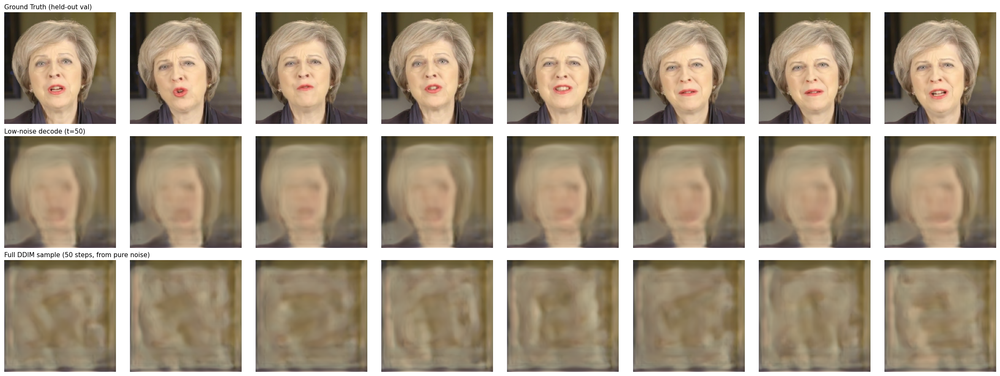

Pairwise mean abs pixel diff - GT: 0.05323  low-noise: 0.02125 (ratio 0.399)  full DDIM: 0.03806 (ratio 0.715)


In [37]:
# --- Visual check: ground truth vs. low-noise decode vs. full DDIM sample ---
# Real held-out validation frames, decoded with the current in-memory model.

@torch.no_grad()
def visualize_genlatent_decoder(num_show=8, low_noise_timestep=50, ddim_steps=50):
    diffusion_decoder.eval()
    patch_pixel_decoder.eval()
    gen_latent_adapter.eval()
    model.eval()

    flat, pooled_state, patch_tok, audio_embed, n = _get_diagnostic_batch(num_frames=num_show)
    gen_latent = gen_latent_adapter(pooled_state, audio_embed)

    num_show = min(num_show, n)
    idx = torch.randperm(n)[:num_show]
    gt = flat[idx]
    tok = patch_tok[idx]
    cond = gen_latent[idx]

    t_low = torch.full((num_show,), low_noise_timestep, device=device, dtype=torch.long)
    noise = torch.randn_like(tok)
    noisy_low = noise_scheduler.add_noise(tok, noise, t_low)
    pred_noise_low = diffusion_decoder(noisy_low, t_low, cond)
    alpha_low = noise_scheduler.alphas_cumprod[t_low].to(device).view(-1, 1, 1)
    denoised_low = (noisy_low - (1 - alpha_low).sqrt() * pred_noise_low) / alpha_low.sqrt()
    decoded_low = patch_pixel_decoder(denoised_low)

    ddim_scheduler.set_timesteps(ddim_steps)
    sample = torch.randn_like(tok)
    for t in ddim_scheduler.timesteps:
        t_batch = torch.full((num_show,), int(t), device=device, dtype=torch.long)
        pred_noise = diffusion_decoder(sample, t_batch, cond)
        sample = ddim_scheduler.step(pred_noise, t, sample).prev_sample
    decoded_ddim = patch_pixel_decoder(sample)

    def to_img(x):
        return x.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(3, num_show, figsize=(num_show * 3, 9))
    row_titles = ["Ground Truth (held-out val)", f"Low-noise decode (t={low_noise_timestep})",
                  f"Full DDIM sample ({ddim_steps} steps, from pure noise)"]
    for row, imgs in enumerate([gt, decoded_low, decoded_ddim]):
        for i in range(num_show):
            axes[row, i].imshow(to_img(imgs[i]))
            axes[row, i].axis("off")
        axes[row, 0].set_title(row_titles[row], loc="left", fontsize=11)
    plt.tight_layout()
    plt.show()

    def mean_pairwise_l1(x):
        n_ = x.size(0)
        total, count = 0.0, 0
        for i in range(n_):
            for j in range(i + 1, n_):
                total += (x[i] - x[j]).abs().mean().item()
                count += 1
        return total / max(count, 1)

    gt_pw = mean_pairwise_l1(gt)
    low_pw = mean_pairwise_l1(decoded_low)
    ddim_pw = mean_pairwise_l1(decoded_ddim)
    print(f"Pairwise mean abs pixel diff - GT: {gt_pw:.5f}  low-noise: {low_pw:.5f} "
          f"(ratio {low_pw/gt_pw:.3f})  full DDIM: {ddim_pw:.5f} (ratio {ddim_pw/gt_pw:.3f})")


visualize_genlatent_decoder()


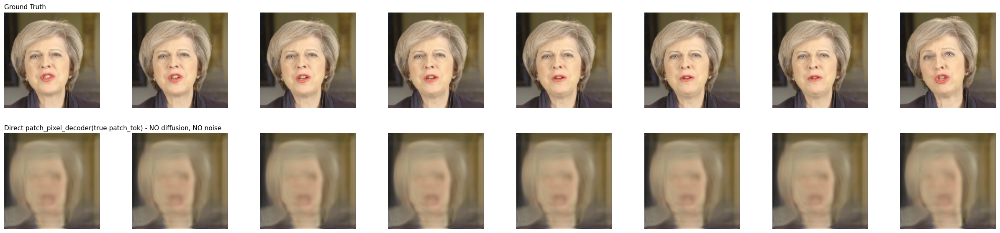

Sharpness proxy (Laplacian variance, higher = sharper): GT=0.004629  direct-decoded=0.000032  ratio=0.007

If direct-decoded is still very blurry relative to GT here (zero noise/diffusion involved),
patch_pixel_decoder's own capacity/training is the bottleneck - not the diffusion process or
the conditioning pipeline. Next lever would be increasing recon_loss_weight (currently a small
secondary term at 0.1 vs. the dominant diff_loss), adding a real perceptual/adversarial loss on
patch_pixel_decoder specifically, or increasing patch_dim / decoder capacity.


{'gt_sharp': 0.004629105678759515,
 'dec_sharp': 3.1727108307677554e-05,
 'ratio': 0.006853831065740462}

In [38]:
@torch.no_grad()
def check_pixel_decoder_direct_reconstruction(num_show=8, seed=42):
    flat, pooled_state, patch_tok, raw_audio, n = _get_diagnostic_batch(num_frames=num_show, seed=seed)
    num_show = min(num_show, n)
    gt = flat[:num_show]
    tok = patch_tok[:num_show]

    direct_decoded = patch_pixel_decoder(tok)  # NO noise, NO diffusion - the true patch_tok, directly

    def to_img(x):
        return x.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(2, num_show, figsize=(num_show * 3, 6))
    for i in range(num_show):
        axes[0, i].imshow(to_img(gt[i])); axes[0, i].axis("off")
        axes[1, i].imshow(to_img(direct_decoded[i])); axes[1, i].axis("off")
    axes[0, 0].set_title("Ground Truth", loc="left", fontsize=11)
    axes[1, 0].set_title("Direct patch_pixel_decoder(true patch_tok) - NO diffusion, NO noise", loc="left", fontsize=11)
    plt.tight_layout()
    plt.show()

    def laplacian_var(x):
        """Crude sharpness proxy: variance of a simple discrete Laplacian. Higher = sharper/more detail."""
        gray = x.mean(dim=0)  # (H, W)
        lap = gray[1:-1, 1:-1] * -4 + gray[:-2, 1:-1] + gray[2:, 1:-1] + gray[1:-1, :-2] + gray[1:-1, 2:]
        return lap.var().item()

    gt_sharp = sum(laplacian_var(gt[i]) for i in range(num_show)) / num_show
    dec_sharp = sum(laplacian_var(direct_decoded[i]) for i in range(num_show)) / num_show
    print(f"Sharpness proxy (Laplacian variance, higher = sharper): GT={gt_sharp:.6f}  "
          f"direct-decoded={dec_sharp:.6f}  ratio={dec_sharp/gt_sharp:.3f}")
    print("\nIf direct-decoded is still very blurry relative to GT here (zero noise/diffusion involved),")
    print("patch_pixel_decoder's own capacity/training is the bottleneck - not the diffusion process or")
    print("the conditioning pipeline. Next lever would be increasing recon_loss_weight (currently a small")
    print("secondary term at 0.1 vs. the dominant diff_loss), adding a real perceptual/adversarial loss on")
    print("patch_pixel_decoder specifically, or increasing patch_dim / decoder capacity.")
    return {"gt_sharp": gt_sharp, "dec_sharp": dec_sharp, "ratio": dec_sharp / gt_sharp if gt_sharp > 0 else float("nan")}


check_pixel_decoder_direct_reconstruction()